Copyright (c) Microsoft Corporation.
Licensed under the MIT License.

<p align="center">
  <img src="./assets/banners/01-build-launch-kit.svg" alt="MAI Models · Multimodal Product Launch — Build the launch kit: How can MAI-Image-2.6 models support a real product launch? Microsoft AI Samples" width="900" />
</p>

# 🎨 One tent, one launch

> **How can MAI-Image-2.6 models support a real product launch — and how would you explain it to a customer?**

⏱️ About 45 minutes (or 15 on the short route) · 🧱 You'll build: a launch kit for the TrailMaster X4 tent

**By the end, you'll be able to:**

- Show each of MAI-Image-2.6's strengths with a picture you made yourself
- Judge an image like a pro, with a checklist instead of a gut feeling
- Explain where it shines, when to use it, and when to pick MAI-Image-2.6-Flash instead

> 🧪 **Heads-up: you can read this one or run it.** In replay mode (the default) it shows saved pictures from an earlier run, in `examples/01/`. Switch to live mode to make your own; every image is a fresh roll of the dice, so yours will look different. That's part of the fun!

> 💡 **How to use this notebook:** run each cell in order with **Shift + Enter**. Before each code cell, read the note and **take a guess** at what you'll see. Guessing wrong is how the lessons stick.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.1 The story: one tent, one afternoon

Back in 2023, Contoso Outdoors sold a tent called the **TrailMaster X4**. It's still one of our favorites.
Now marketing wants to relaunch it, and they need *everything*. Posters, a catalog page, close-ups, a setup
guide and lifestyle photos. Ads in other languages, a web banner and a phone story.

Normally that's weeks of photo shoots and design rounds. Today, let's see how far **one image model** can take
us in an afternoon. And at each step, we'll ask the question a customer would ask.

Here's the tent, straight from the original 2023 catalog:

| | TrailMaster X4 Tent |
| --- | --- |
| **Brand** | OutdoorLiving |
| **Price** | $250 |
| **Sleeps** | 4 people |
| **Keeps you dry** | Water-resistant polyester, plus a rainfly |
| **Keeps you comfy** | Mesh panels for airflow and bug defence, several doors, interior pockets |
| **Keeps you safe** | Reflective guylines you can see at night |
| **Goes where you go** | Freestanding, with a carry bag |

### Pick your route

| Route | Sections | Good for |
| --- | --- | --- |
| ⚡ **Short** (about 15 minutes) | 1.4, 1.5, 1.9, 1.13, 1.16, 1.17 | A first look before a customer meeting |
| 🧭 **Full** (about 45 minutes) | All of them | Learning every feature well enough to teach it |

Every section opens with **🧭 the customer's question**. Keep those handy. They're the questions you'll hear.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.2 New words

| Word | In plain words |
| --- | --- |
| **Image generation model** | A model that draws a picture from a description |
| **Image editing** | Changing a picture you already have, like removing a person or changing a price |
| **Reference image** | A picture you hand the model to say *"this one, exactly this"*. MAI-Image takes up to five |
| **Aspect ratio** | A picture's shape: wide like a banner, tall like a phone story, or square |
| **Web grounding** | Letting the model look things up on the web (with Bing) before it draws |
| **Flash version** | A faster, cheaper version of the same model |
| **Rate limit** | How many requests your deployment accepts each minute |
| **Latency** | How long you wait for one picture |

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.3 Before you start

**Just reading?** Run the next cell, then go to 1.4: replay mode needs no Azure at all.

**Running it live?** You need four things. Running `bash infra/setup.sh` from this folder gives you all of them.

| You need | How to check |
| --- | --- |
| A **Microsoft Foundry project** | This folder's `.env` has `FOUNDRY_PROJECT_ENDPOINT` |
| A **MAI-Image-2.6** deployment | **Models + endpoints** in the [Foundry portal](https://ai.azure.com) lists it |
| A **MAI-Image-2.6-Flash** deployment, for section 1.16 | Same place |
| The **Foundry User** role, and a sign-in | Run `az login` in a terminal |

**Need to sign in?** Run this once in a terminal and complete the flow, then restart here:

```bash
az login --use-device-code
```

**What it costs.** A full run makes about 47 images, on pay-as-you-go pricing. Look up today's prices on the
[official pricing page](https://aka.ms/MAIModelPricing). If you add them to `.env`, section 1.17 adds up your bill.

**How long it takes.** Each deployment has a **rate limit**: a set number of requests a minute. The notebook reads it
from `RATE_LIMIT_RPM` in `.env` (6 if unset) and spaces out its requests to match, so some cells wait a little.
That's the speed limit, not a bug.

> 🎬 **Replay or live?** The next cell shows which mode you're in. **Replay** (the default) shows saved pictures from `examples/01/` and needs no Azure. **Live** makes your own, saved in `output/01/`; replay then shows yours first. To switch, set `DEMO_MODE` in the next cell, or add `DEMO_MODE=live` to this folder's `.env`.

In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "contoso-retail").is_dir())
load_dotenv(ROOT / "workshops" / "mai-multimodal-product-launch" / ".env")

DEMO_MODE = None  # ✏️ Set to "live" or "replay" to override .env. Leave None to use .env.

mode = (DEMO_MODE or os.environ.get("DEMO_MODE") or "replay").strip().lower()
if mode not in ("replay", "live"):
    raise SystemExit(f'⚠️ DEMO_MODE is "{mode}". Use "replay" or "live".')
source = "this cell" if DEMO_MODE else ".env" if os.environ.get("DEMO_MODE") else "the default"
print(f"🎬 Mode: {'🔁 replay' if mode == 'replay' else '🎨 live'} (from {source})")

🎬 Mode: 🔁 replay (from .env)


<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.4 Get set up

Three small cells. The first loads your settings and signs you in **without a key**: Azure uses your
`az login` sign-in instead.

> 🔮 **Guess first:** which two model names will it print?

In [2]:
# Settings come from this folder's .env, which infra/setup.sh writes, so no names or secrets are written into the code.
import base64
import io
import json
import os
import random
import statistics
import threading
import time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from datetime import date
from pathlib import Path
from urllib.parse import urlparse

import requests
from azure.identity import DefaultAzureCredential
from dotenv import load_dotenv
from IPython.display import HTML, display
from PIL import Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "contoso-retail").is_dir())
HERE = ROOT / "workshops" / "mai-multimodal-product-launch"
load_dotenv(HERE / ".env")


def setting(name: str, default: str | None = None) -> str:
    """Return a setting from .env, or stop with a message that says how to fix it."""
    value = os.environ.get(name, "").strip()
    if value and "<" not in value:
        return value
    if default is not None:
        return default
    raise SystemExit(f"⚠️ {name} isn't set yet. Run `bash infra/setup.sh` (it writes .env), then run this cell again.")


# The mode cell in 1.3 wins over .env. Replay shows saved pictures and needs no Azure, so the model names get defaults there.
REPLAY = (globals().get("DEMO_MODE") or setting("DEMO_MODE", "replay")).strip().lower() == "replay"
HERO = setting("MODEL_IMAGE_HERO", "MAI-Image-2.6" if REPLAY else None)         # Best quality, for pictures people will study
FLASH = setting("MODEL_IMAGE_BULK", "MAI-Image-2.6-Flash" if REPLAY else None)  # Faster and cheaper, for volume
REQUESTS_PER_MINUTE = int(setting("RATE_LIMIT_RPM", "6"))

OUTPUT = HERE / "output" / "01"      # Your pictures. Git ignores this folder.
EXAMPLES = HERE / "examples" / "01"  # Pictures from one of our runs, so anyone can replay the demo
OUTPUT.mkdir(parents=True, exist_ok=True)
LOG_FILE = OUTPUT / "run_log.json"
run_log: dict[str, dict] = json.loads(LOG_FILE.read_text()) if LOG_FILE.exists() else {}
example_log: dict[str, dict] = json.loads((EXAMPLES / "run_log.json").read_text()) if (EXAMPLES / "run_log.json").exists() else {}

credential = DefaultAzureCredential()  # Keyless: uses your az login, not a secret key.

print(f"✅ Settings loaded. Best quality: {HERO} · Faster: {FLASH}")
print(f"   Spacing requests for {REQUESTS_PER_MINUTE} per minute · Mode: {'🔁 replay (your pictures first, then examples/01/)' if REPLAY else '🎨 live'}")

✅ Settings loaded. Best quality: MAI-Image-2.6 · Faster: MAI-Image-2.6-Flash
   Spacing requests for 5 per minute · Mode: 🔁 replay (your pictures first, then examples/01/)


The second cell holds our two helpers, one for each MAI image API:

- `generate(prompt, ...)` draws a **new** picture from words.
- `edit(prompt, references, ...)` makes a picture from **one to five pictures you already have**, plus words.

Both save the picture in `output/01/`, time it, and space out requests so you stay under your rate limit.

In [3]:
HINTS = {
    400: "The model didn't accept something. Check the size (each side 768 or more, 2,359,296 pixels at most), the image type (PNG or JPEG) and the options.",
    401: "Sign-in failed. Run `az login` in a terminal, then run this cell again.",
    403: "You're signed in, but you don't have permission yet. Ask for the Foundry User role on the Foundry resource.",
    404: "There's no deployment with that name. Compare MODEL_IMAGE_HERO and MODEL_IMAGE_BULK in .env with Models + endpoints in the Foundry portal. Not deployed yet? See section 1.3.",
}
_next_turn: dict[str, float] = defaultdict(float)
_turn_locks: dict[str, threading.Lock] = defaultdict(threading.Lock)
_log_lock = threading.Lock()


def _wait_for_turn(model: str) -> None:
    # Each deployment accepts a set number of requests a minute. Spacing them out beats hitting the limit.
    with _turn_locks[model]:
        wait = _next_turn[model] - time.monotonic()
        if wait > 0:
            time.sleep(wait)
        _next_turn[model] = time.monotonic() + 60 / REQUESTS_PER_MINUTE


def _call(api: str, model: str, **request) -> tuple[dict, float]:
    """Send one request to the MAI image API. Returns the reply and how many seconds the model took."""
    if REPLAY:
        raise SystemExit("🔁 Replay has no saved result for this request. Set DEMO_MODE to live to send it.")
    for _ in range(4):
        _wait_for_turn(model)
        token = credential.get_token("https://cognitiveservices.azure.com/.default").token
        started = time.perf_counter()  # Start the clock after the wait, so we time the model, not the queue.
        reply = requests.post(f"https://{urlparse(setting('FOUNDRY_PROJECT_ENDPOINT')).hostname}/mai/v1/images/{api}", headers={"Authorization": f"Bearer {token}"}, timeout=300, **request)
        seconds = time.perf_counter() - started
        if reply.status_code == 429 or reply.status_code >= 500:
            pause = round(float(reply.headers.get("Retry-After", "20")))
            print(f"   ⏳ {model} is busy ({reply.status_code}). Waiting {pause} seconds, then trying again…")
            time.sleep(pause)
            continue
        if reply.ok:
            return reply.json(), seconds
        hint = HINTS.get(reply.status_code, "The message below usually says what to change.")
        try:
            detail = reply.json().get("error", {}).get("message", "")[:300]
        except ValueError:
            detail = ""
        raise SystemExit(f"⚠️ {reply.status_code} from {model}. {hint}\n{detail}")
    raise SystemExit("⚠️ Still busy after four tries. Wait a minute, then run the cell again.")


def _keep(name: str, model: str, seconds: float, reply: dict) -> Path:
    """Save the picture, and note which model made it and how long it took."""
    path = OUTPUT / f"{name}.png"
    path.write_bytes(base64.b64decode(reply["data"][0]["b64_json"]))
    width, height = Image.open(path).size
    with _log_lock:
        run_log[name] = {"model": model, "seconds": round(seconds, 1), "size": f"{width}×{height}"}
        # Only your own pictures go in your log, never the replayed examples.
        LOG_FILE.write_text(json.dumps({key: value for key, value in run_log.items() if (OUTPUT / f"{key}.png").exists()}, indent=2))
    print(f"🖼️ {name} · {model} · {seconds:.1f} s · {width}×{height}")
    return path


def saved(name: str) -> Path | None:
    """Where a saved picture lives: output/01/ (yours) first, then examples/01/ (ours)."""
    for path in (OUTPUT / f"{name}.png", EXAMPLES / f"{name}.webp"):
        if path.exists():
            return path
    return None


def _replayed(name: str) -> Path | None:
    if not REPLAY:
        return None
    path = saved(name)
    entry = run_log.get(name) if path and path.parent == OUTPUT else example_log.get(name)
    if not (path and entry):
        return None
    run_log[name] = entry  # So the times and sizes work in every later cell
    where = "saved earlier" if path.parent == OUTPUT else "from examples/01/"
    print(f"🔁 {name} · {entry['model']} · {entry['seconds']} s ({where}) · {entry['size']}")
    return path


def generate(prompt: str, name: str, model: str = HERO, size: tuple[int, int] | None = (1024, 1024), **options) -> Path:
    """Draw a new picture from words. Use size=None with auto_aspect_ratio=True to let the model pick the shape."""
    if saved := _replayed(name):
        return saved
    body = {"model": model, "prompt": prompt, **options}
    if size:
        body["width"], body["height"] = size
    reply, seconds = _call("generations", model, json=body)
    return _keep(name, model, seconds, reply)


def _as_upload(ref: Path) -> tuple[str, bytes, str]:
    """The edits API takes PNG or JPEG, so a saved WebP example is sent as PNG."""
    if ref.suffix.lower() in (".png", ".jpg", ".jpeg"):
        return ref.name, ref.read_bytes(), "image/png" if ref.suffix.lower() == ".png" else "image/jpeg"
    buffer = io.BytesIO()
    Image.open(ref).save(buffer, "PNG")
    return ref.with_suffix(".png").name, buffer.getvalue(), "image/png"


def edit(prompt: str, references: list[Path], name: str, model: str = HERO, **options) -> Path:
    """Make a new picture from one to five reference pictures, plus words."""
    if saved := _replayed(name):
        return saved
    files = [("image", _as_upload(ref)) for ref in references]
    # The edits API takes a form, not JSON, so true and false travel as text.
    form = {"model": model, "prompt": prompt, **{key: str(value).lower() for key, value in options.items()}}
    reply, seconds = _call("edits", model, data=form, files=files)
    return _keep(name, model, seconds, reply)


print("✅ Helpers ready: generate() and edit()")

✅ Helpers ready: generate() and edit()


The third cell is about *looking*. `show()` lines pictures up side by side. `before_after()` gives you a slider
you can drag to compare an edit. We also write down how the tent looks, so every picture shows the same tent.

In [4]:
def _inline(path: Path, height: int) -> str:
    # A small JPEG copy keeps the notebook light, even when the original is 1536 pixels wide.
    picture = Image.open(path).convert("RGB")
    picture.thumbnail((height * 8, height * 2))
    buffer = io.BytesIO()
    picture.save(buffer, "JPEG", quality=88)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()


def show(pictures: dict[str, Path], height: int = 300) -> None:
    """Show pictures side by side, each with a caption."""
    cards = "".join(
        f'<figure style="display:inline-block;margin:0 12px 12px 0;vertical-align:top;text-align:center">'
        f'<img src="{_inline(path, height)}" style="height:{height}px;border-radius:8px"/>'
        f'<figcaption style="font-size:13px;margin-top:4px">{caption}</figcaption></figure>'
        for caption, path in pictures.items()
    )
    display(HTML(f"<div>{cards}</div>"))


def before_after(before: Path, after: Path, height: int = 420) -> None:
    """Drag the slider to wipe between a picture and its edit."""
    key = f"wipe{random.randrange(10**9)}"
    width = round(height * Image.open(before).width / Image.open(before).height)
    box = f"position:absolute;top:0;left:0;width:{width}px;height:{height}px;object-fit:cover;border-radius:8px"
    display(HTML(f"""
    <div style="position:relative;width:{width}px;height:{height}px">
      <img src="{_inline(after, height)}" style="{box}"/>
      <img id="{key}" src="{_inline(before, height)}" style="{box};clip-path:inset(0 50% 0 0)"/>
    </div>
    <input type="range" min="0" max="100" value="50" style="width:{width}px"
      oninput="document.getElementById('{key}').style.clipPath='inset(0 '+(100-this.value)+'% 0 0)'"/>
    <div style="font-size:13px">◀ before · after ▶ <i>(Slider stuck? Your viewer blocks scripts. Use show() instead.)</i></div>"""))


# How the tent looks, written once, so every picture shows the same tent.
TENT = "TrailMaster X4 Tent"
LOOK = ("a four-person dome tent with a forest-green body, a burnt-orange rainfly, black mesh panels, "
        "grey reflective guylines and a small white 'OutdoorLiving' logo on the front door")

print("✅ Ready to make a launch kit for the", TENT)

✅ Ready to make a launch kit for the TrailMaster X4 Tent


<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.5 Cold open: a launch poster from one prompt

<img src="./assets/asks/01-05.svg" alt="Your customer asks: Can it put real words on a picture? We always fix the text by hand afterwards." width="900" />
<br/>

Text has been the weak spot of image models for years: misspelled headlines, melted letters, prices that turn
into squiggles. MAI-Image-2.6 was built to be better at it. So let's start with the hardest test: a full poster,
with a headline, a product name, a price badge, feature lines and a footer.

> 🔮 **Guess first:** of the five pieces of text, how many will come out spelled exactly right?

🔁 05-launch-poster · MAI-Image-2.6 · 50.9 s (saved earlier) · 1024×1536



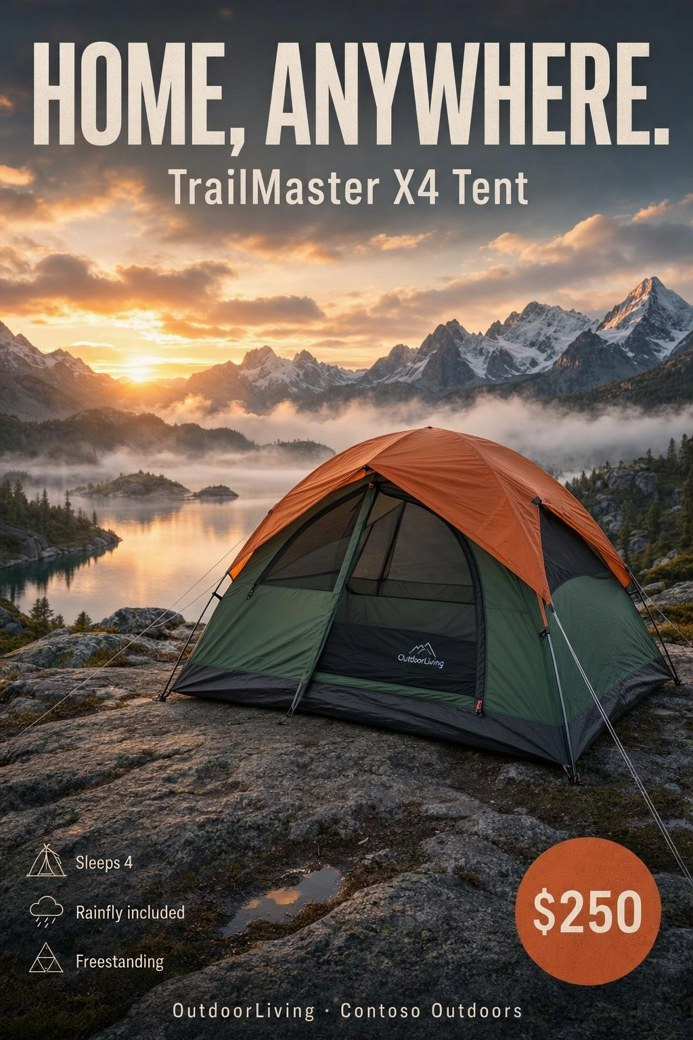

In [5]:
POSTER = f"""A magazine-cover style launch poster for the {TENT}.
Photo: {LOOK}, pitched on a granite ledge above a misty alpine lake at sunrise.
Text, exactly as written, from most to least important:
1. Huge bold condensed headline across the top: "HOME, ANYWHERE."
2. Under it, medium weight: "TrailMaster X4 Tent"
3. A round burnt-orange price badge in the lower right: "$250"
4. Three short lines with small line icons, lower left: "Sleeps 4" / "Rainfly included" / "Freestanding"
5. Small footer along the bottom: "OutdoorLiving · Contoso Outdoors"
Clean layout with generous margins. No other text."""

poster = generate(POSTER, "05-launch-poster", size=(1024, 1536))
show({"Launch poster · MAI-Image-2.6": poster}, height=520)

👀 **What to look for:**

- [ ] Is every word spelled exactly as written? Check the price and the dot in the footer too.
- [ ] Does the **hierarchy** work? Your eye should land on the headline, then the name, then the price.
- [ ] Is the tent the one we described: green body, orange rainfly, white logo?

⚠️ **The honest limit:** small text is the hardest. If a footer letter wobbles, run the cell again. Every run is a new roll.

🧪 **Try it yourself:** change the headline to something longer, like *"Your new favorite room has no walls"*. Does the layout still hold?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.6 The brief that grew up

<img src="./assets/asks/01-06.svg" alt="Your customer asks: Will it follow our brand guide, or will everything look generic?" width="900" />
<br/>

Here's a fun experiment. We send three briefs for the same poster: **5 words**, then **about 50**, then a
**full page of brand guide**. MAI-Image-2.6 reads prompts up to 32,000 tokens long. That's room for a whole
brand book, not just a sentence.

> 🔮 **Guess first:** will the longest brief look *better*, or just *busier*?

📝 short brief: 5 words
📝 medium brief: 58 words
📝 long brief: 279 words
🔁 06-brief-short · MAI-Image-2.6 · 26.9 s (saved earlier) · 1024×1280
🔁 06-brief-medium · MAI-Image-2.6 · 27.7 s (saved earlier) · 1024×1280
🔁 06-brief-long · MAI-Image-2.6 · 27.8 s (saved earlier) · 1024×1280



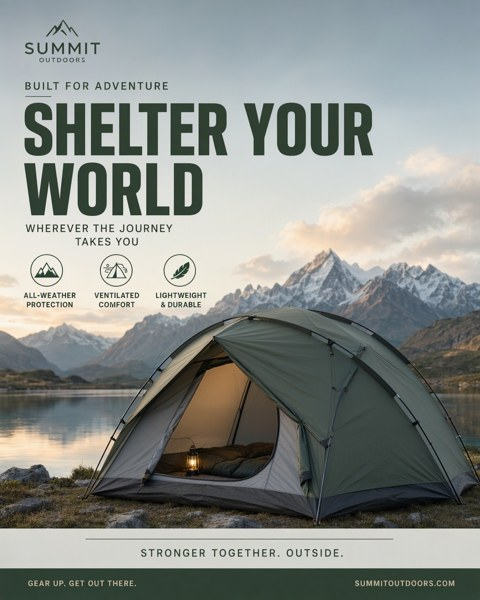
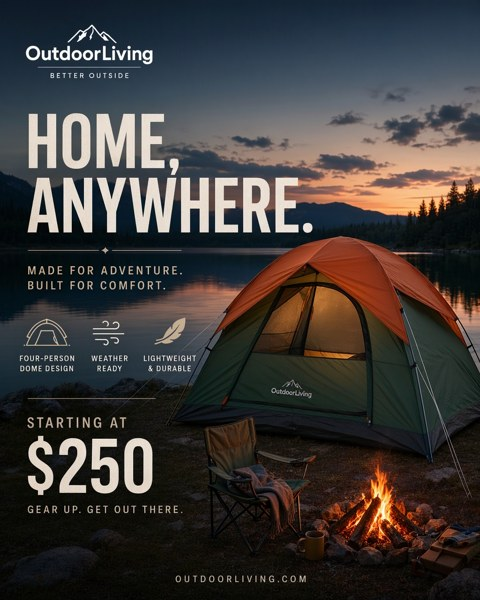
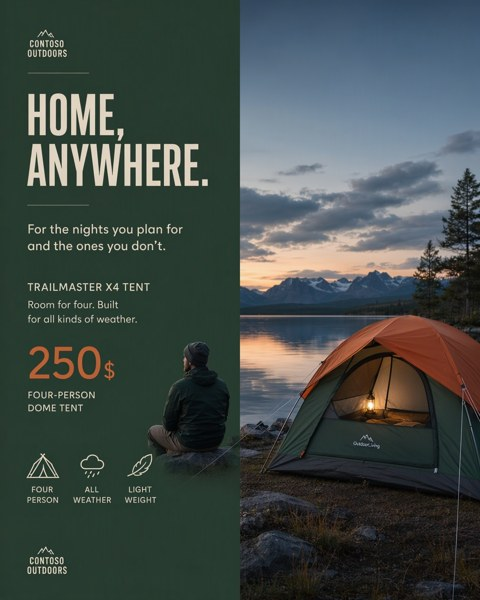

In [6]:
SHORT_BRIEF = "A poster for a tent."

MEDIUM_BRIEF = f"""A poster for the {TENT} by OutdoorLiving: {LOOK}, at a lakeside campsite at dusk.
Headline: "HOME, ANYWHERE." Price: "$250". Warm, friendly and outdoorsy, with lots of space around the text."""

BRAND_GUIDE = """CONTOSO OUTDOORS BRAND GUIDE (summary for designers)
Voice: warm, unhurried and a little playful. We sell the feeling of arriving, not the gear itself.
Colors: Forest Green #2F5D3A for backgrounds and large shapes. Burnt Orange #D9692B only for one accent per layout,
usually the price or a call to action. Bone #F3EDE2 for text panels. Never pure black or pure white.
Type: headlines in a heavy condensed sans-serif, all caps, tight letter spacing. Body text in a friendly rounded
sans-serif. Never more than three type sizes on one layout. Left-align text; never center long lines.
Photography: real places, real weather, natural light. Golden hour or blue hour. People shown from behind or in
profile, looking at the view, never posing at the camera. Gear looks used but cared for: a little dust is fine.
Composition: the product takes up no more than a third of the frame. Leave a calm, empty area for text. Horizon
lines sit on the lower third. One clear focal point per layout.
Logo: the small 'Contoso Outdoors' wordmark sits in the bottom-left corner, in Bone, never on a busy background.
Avoid: lens flare, heavy filters, neon colors, stock-photo smiles, drop shadows on text, more than one exclamation mark.
"""

LONG_BRIEF = f"""{BRAND_GUIDE}
THE JOB: a launch poster for the {TENT} by OutdoorLiving: {LOOK}.
Scene: blue hour at a quiet lakeside campsite, a lantern glowing inside the tent, one hiker seen from behind on the shore.
Headline: "HOME, ANYWHERE." Price, as the single orange accent: "$250". Follow the brand guide exactly."""

for label, brief in [("short", SHORT_BRIEF), ("medium", MEDIUM_BRIEF), ("long", LONG_BRIEF)]:
    print(f"📝 {label} brief: {len(brief.split())} words")

briefs = {
    f"{len(brief.split())} words": generate(brief, f"06-brief-{label}", size=(1024, 1280))
    for label, brief in [("short", SHORT_BRIEF), ("medium", MEDIUM_BRIEF), ("long", LONG_BRIEF)]
}
show(briefs)

👀 **What to look for:** pick three rules from the brand guide and check them in the third picture. 
- One orange accent only? 
- Logo bottom left? 
- Hiker seen from behind? 
Each rule it follows is one less round of feedback.

⚠️ **The honest limit:** a model follows *most* rules, not always *all* of them. With customers, say
*"fewer revision rounds"*, not *"no revisions"*.

🧪 **Try it yourself:** add one strict rule to `BRAND_GUIDE`, like *"Every headline ends with a period"*, and
run it again. Did it notice?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.7 Around the world in four cells

<img src="./assets/asks/01-07.svg" alt="Your customer asks: We sell in twelve countries. Can it make our ads in other languages?" width="900" />
<br/>

This one's an **honest test**, and that makes it one of the most useful sections. MAI-Image-2.6's model card
says text in images is *optimized for English*. So let's find out together what that means in practice.

Notice the trick: the **instructions stay in English**, and only the words *on the poster* change language.
The model card says the model reads prompts in English, so that's the fairest test.

> 🔮 **Guess first:** rank English, Spanish and Japanese from best to worst text.

🔁 07-ad-english · MAI-Image-2.6 · 24.5 s (saved earlier) · 1024×1024
🔁 07-ad-spanish · MAI-Image-2.6 · 24.2 s (saved earlier) · 1024×1024
🔁 07-ad-japanese · MAI-Image-2.6 · 22.8 s (saved earlier) · 1024×1024



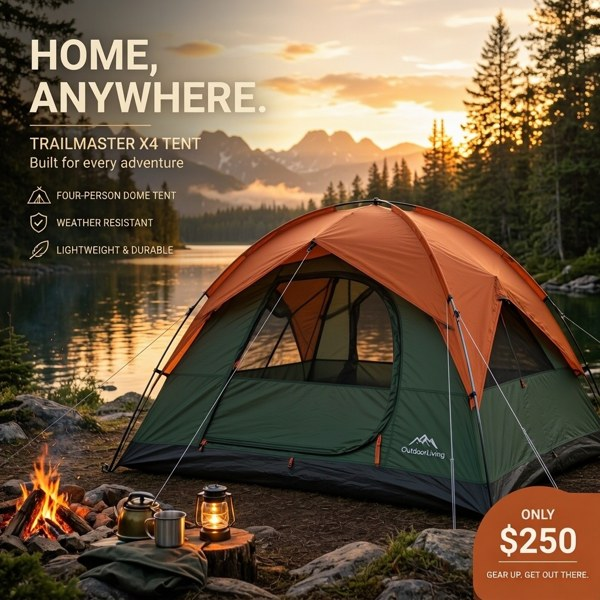
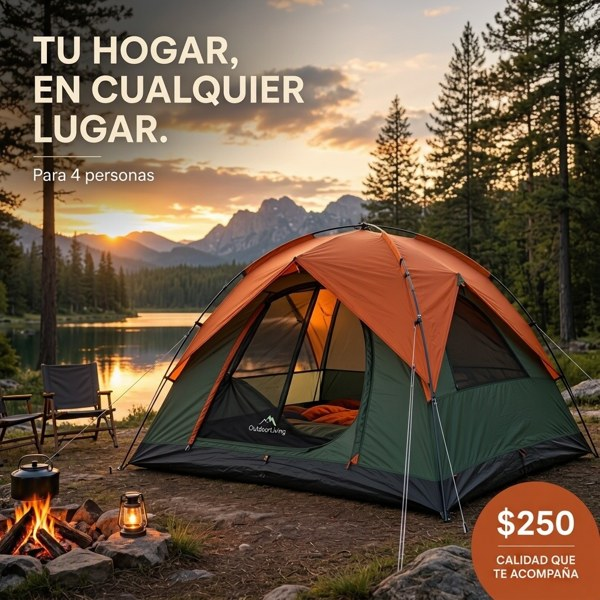
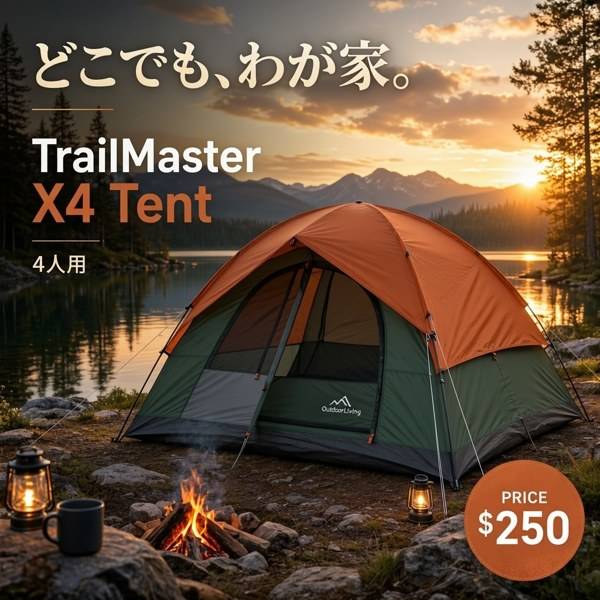

In [7]:
HEADLINES = {
    "English": ("HOME, ANYWHERE.", "Sleeps 4"),
    "Spanish": ("TU HOGAR, EN CUALQUIER LUGAR.", "Para 4 personas"),
    "Japanese": ("どこでも、わが家。", "4人用"),
}

localized = {}
for language, (headline, sleeps) in HEADLINES.items():
    prompt = f"""A clean outdoor ad for the {TENT}: {LOOK}, at a forest campsite at golden hour.
Write this text exactly, in {language}, keeping every character and accent:
Headline at the top: "{headline}"
Small line under the product: "{sleeps}"
Price badge: "$250"
The same layout every time: headline top left, badge bottom right."""
    localized[language] = generate(prompt, f"07-ad-{language.lower()}", size=(1024, 1024))

show(localized)

👀 **What to look for:** check accents in Spanish (*í*, *ñ* if any) and every Japanese character. A native
speaker on your team is the best judge. Ask them!

⚠️ **The honest limit:** expect English to be the strongest. For other languages, tell customers to **review
every word**, or to add the text afterwards with their usual design tools.

🧪 **Try it yourself:** add Arabic, which reads right to left: `"Arabic": ("بيتك في أي مكان", "يتسع لأربعة")`.
Does the layout flip, too?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.8 One tent, every season

<img src="./assets/asks/01-08.svg" alt="Your customer asks: We have forty colorways. Will they all look like the same product?" width="900" />
<br/>

Catalog pages need **coordinated variants**: the same product, the same angle, the same labels, with only the
color and the setting changing. Let's ask for a four-panel catalog page in a single picture.

> 🔮 **Guess first:** what's most likely to drift between panels: the shape, the logo or the labels?

🔁 08-four-seasons · MAI-Image-2.6 · 36.6 s (saved earlier) · 1536×1536



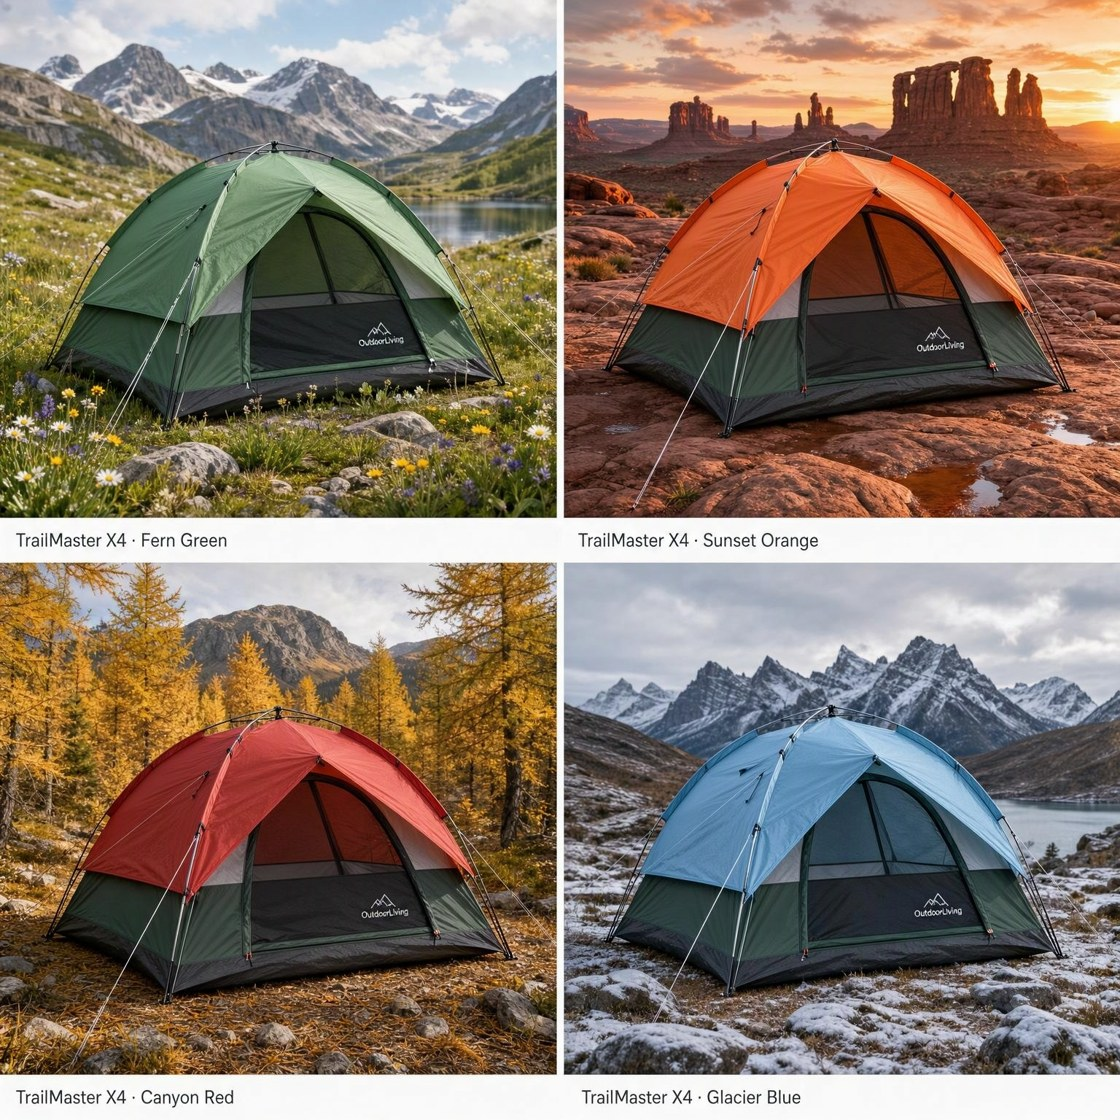

In [8]:
CATALOG = f"""A 2x2 product catalog page, four equal panels separated by thin white gutters.
Every panel shows the same tent model from the same three-quarter front angle: {LOOK.replace("a burnt-orange rainfly", "a rainfly")}.
Keep the tent's shape, pole layout, door, logo position and guylines identical in all four panels.
Only the rainfly color and the setting change:
- Top left: fern-green rainfly, spring meadow with wildflowers. Label: "TrailMaster X4 · Fern Green"
- Top right: sunset-orange rainfly, red desert slickrock. Label: "TrailMaster X4 · Sunset Orange"
- Bottom left: canyon-red rainfly, golden autumn larch forest. Label: "TrailMaster X4 · Canyon Red"
- Bottom right: glacier-blue rainfly, a late-season dusting of snow. Label: "TrailMaster X4 · Glacier Blue"
Each label sits in a white strip along the bottom of its panel, in the same font, size and position."""

catalog = generate(CATALOG, "08-four-seasons", size=(1536, 1536))
show({"Four colorways, one tent": catalog}, height=560)

👀 **What to look for:**

- [ ] Same tent shape and pole layout in all four panels?
- [ ] Logo in the same spot each time?
- [ ] Four labels, same font, same position, each matching its color?

⚠️ **The honest limit:** small details like the logo drift first. For a catalog of hundreds, make one approved
picture and **edit** it per color (you'll see how in section 1.12). Edits keep more of the original.

🧪 **Try it yourself:** change the four panels to four *materials* instead: canvas, ripstop nylon, silnylon and Dyneema.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.9 Touch test

<img src="./assets/asks/01-09.svg" alt="Your customer asks: Up close, does it still look real? Our customers zoom in." width="900" />
<br/>

Materials are where pictures give themselves away. So here are four extreme close-ups, each testing something
different: **texture**, **reflection**, **transparency** and **deformation** (how things squash and bend).

> 🎲 **Make it a game:** before you look at the captions, show these to someone and ask *"real photo or AI?"*

🔁 09-touch-texture · MAI-Image-2.6 · 22.3 s (saved earlier) · 1024×1024
🔁 09-touch-reflection · MAI-Image-2.6 · 23.1 s (saved earlier) · 1024×1024
🔁 09-touch-transparency · MAI-Image-2.6 · 22.8 s (saved earlier) · 1024×1024
🔁 09-touch-deformation · MAI-Image-2.6 · 24.2 s (saved earlier) · 1024×1024



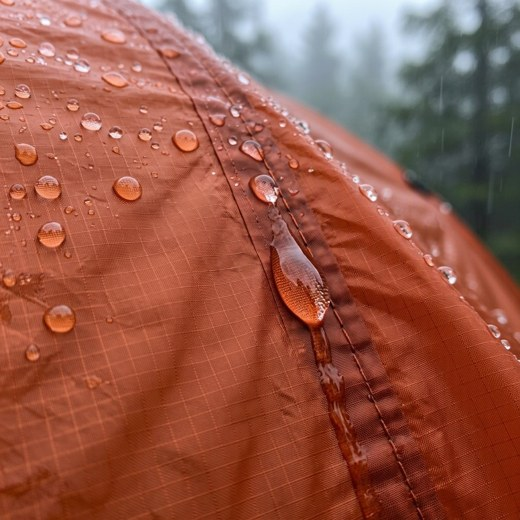
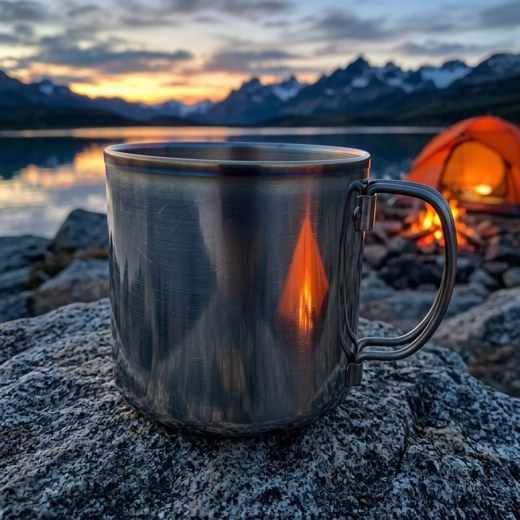
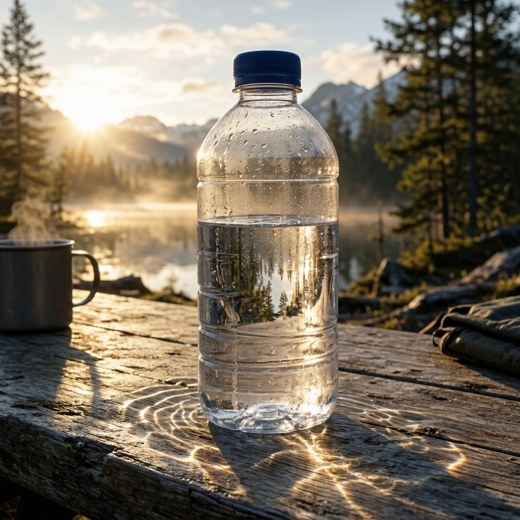
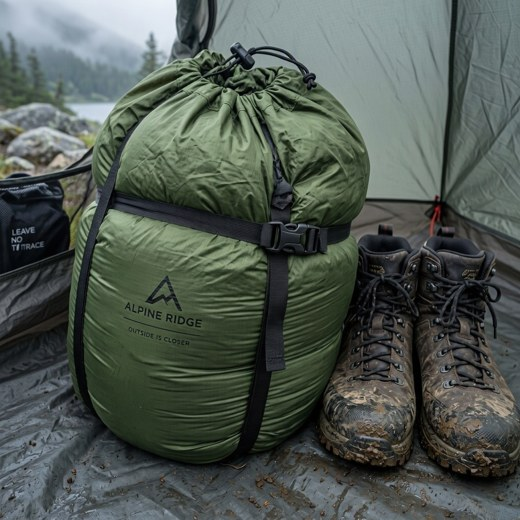

In [9]:
MATERIALS = {
    "texture": "Extreme macro photo of rain on a burnt-orange ripstop polyester tent rainfly: round water beads sitting on the visible fabric weave, two beads merging and running down a taped seam, overcast light, shallow depth of field.",
    "reflection": "Close-up of a brushed titanium camping mug on a granite rock at dusk: faint blue-gold heat tint near the rim, fine scratches, and an orange tent and a small campfire reflected and stretched across the mug's curved side.",
    "transparency": "A clear water bottle, half full, standing on a weathered wooden camp table in low morning sun: light bending through the water and casting a bright rippled pattern on the wood, the forest behind seen upside down through the bottle, condensation drops on the outside.",
    "deformation": "A green nylon stuff sack crammed with a sleeping bag, compression straps pulled tight so the fabric bulges and wrinkles between them, one plastic buckle visibly under strain, lying on a tent floor next to muddy boots.",
}
close_ups = {kind.title(): generate(prompt, f"09-touch-{kind}", size=(1024, 1024)) for kind, prompt in MATERIALS.items()}
show(close_ups, height=260)

👀 **What to look for:** the physics. Do the water beads sit *on* the weave? Is the reflection bent by the curve
of the mug? Is the forest flipped inside the bottle? Do the wrinkles bunch up *between* the straps?

⚠️ **The honest limit:** look at the edges, where two materials meet. That's where small mistakes hide.

🧪 **Try it yourself:** add a fifth close-up for something *you* sell. Fabric, glass, metal, food: what's the hardest material in your customer's catalog?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.10 Clockwork challenge

<img src="./assets/asks/01-10.svg" alt="Your customer asks: Our briefs are really specific. Will it actually do what we ask?" width="900" />
<br/>

Here's a brief with seven exact details. There's a time on a watch, things to the *left* and *under*, one mug
upright and one tipped over, and an exact count. Then **you** become the judge, with a scorecard. A scorecard turns
*"looks good"* into a number you can compare, which is the start of a real **evaluation**.

> 🔮 **Guess first:** out of 7, what will it score? Write your guess down.

🔁 10-clockwork · MAI-Image-2.6 · 27.5 s (saved earlier) · 1536×1024



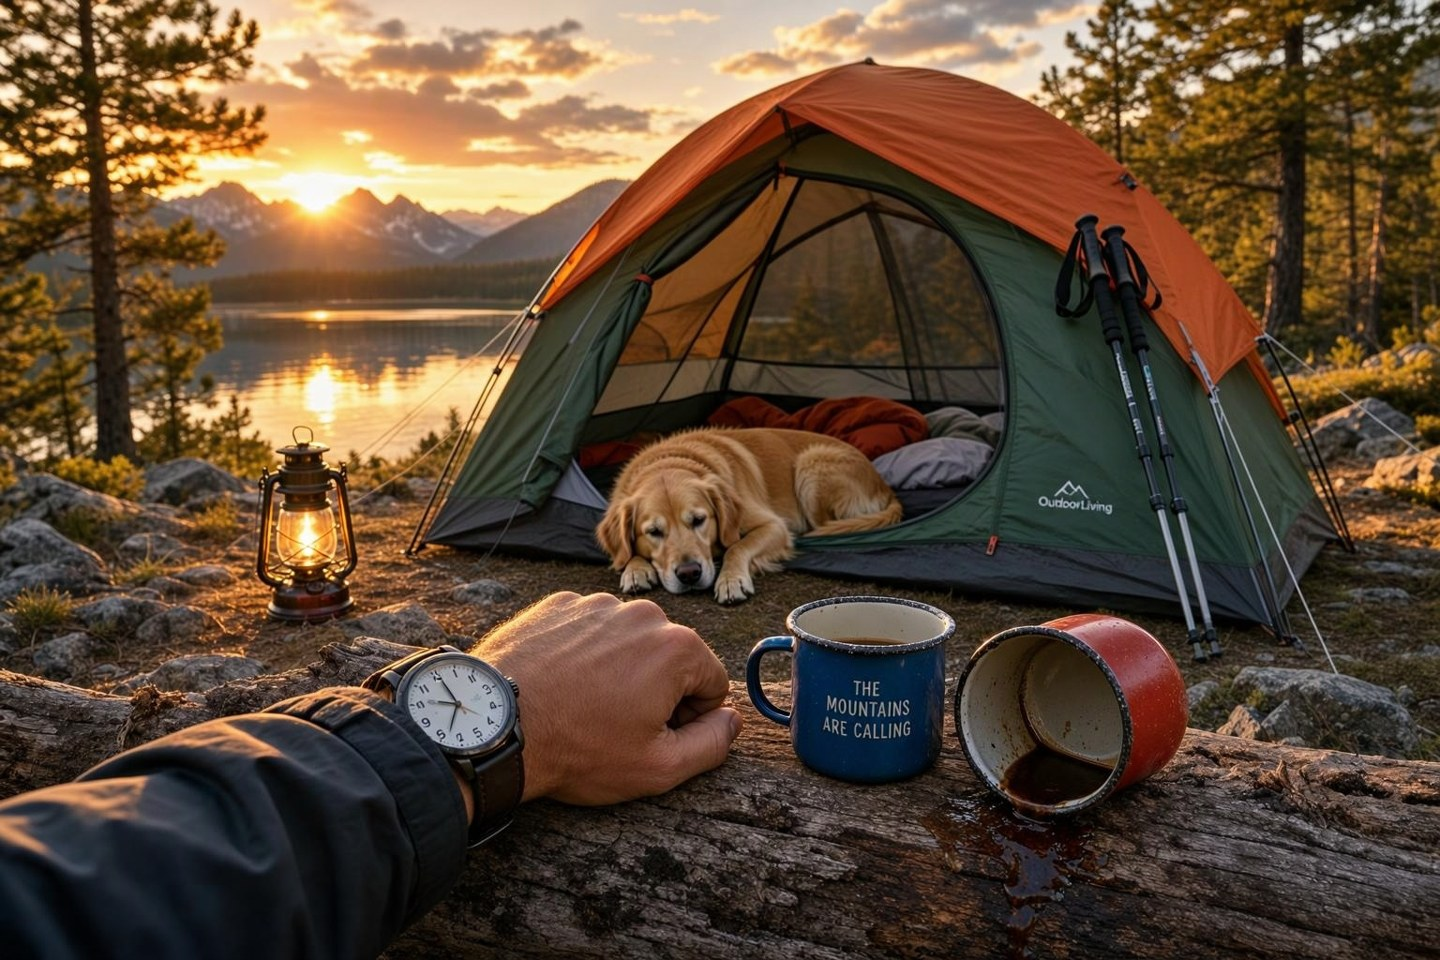

In [10]:
CLOCKWORK = f"""Photo of a campsite at golden hour.
Foreground: a hiker's left wrist resting on a log, wearing an analog watch with a white face. The hands clearly show 6:45.
Behind: the {TENT}, {LOOK}, with its front door rolled open.
A lit lantern stands on the ground to the LEFT of the open door.
A golden retriever sleeps curled up under the tent's vestibule.
On the log next to the wrist: a blue enamel mug standing upright, and a red enamel mug tipped over on its side with coffee spilling onto the wood.
Exactly three trekking poles lean against the right side of the tent."""

clockwork = generate(CLOCKWORK, "10-clockwork", size=(1536, 1024))
show({"Seven details. How many made it?": clockwork}, height=480)

Now score it. Change each `None` to `True` (it's there) or `False` (it isn't), then run the cell.

In [11]:
# ✏️ Your turn to be the judge.
'''
scorecard = {
    "The watch shows 6:45": None,
    "The tent door is open": None,
    "The lantern is LEFT of the door": None,
    "A dog is asleep under the vestibule": None,
    "The blue mug is upright": None,
    "The red mug is tipped over, spilling": None,
    "Exactly three trekking poles, on the right": None,
}
'''

# My results copied and updated
scorecard = {
    "The watch shows 6:45": False,
    "The tent door is open": True,
    "The lantern is LEFT of the door": True,
    "A dog is asleep under the vestibule": True,
    "The blue mug is upright": True,
    "The red mug is tipped over, spilling": True,
    "Exactly three trekking poles, on the right": False,
}

scored = {check: result for check, result in scorecard.items() if result is not None}
if not scored:
    print("✏️ Fill in the scorecard above first. True or False for each line.")
else:
    for check, result in scored.items():
        print(f"{'✅' if result else '❌'} {check}")
    print(f"\n🎯 Score: {sum(scored.values())} out of {len(scored)}")

❌ The watch shows 6:45
✅ The tent door is open
✅ The lantern is LEFT of the door
✅ A dog is asleep under the vestibule
✅ The blue mug is upright
✅ The red mug is tipped over, spilling
❌ Exactly three trekking poles, on the right

🎯 Score: 5 out of 7


👀 **What to look for:** which kind of detail did it get right? Many models nail *what's there* but slip on
*where* (left vs right) or *how many*. Clock times are a classic trap.

⚠️ **The honest limit:** one run is one sample. Run it three times and average your scores before you tell a
customer a number. That's how fair evaluations work.

🧪 **Try it yourself:** change the time to 10:10, the classic watch-ad time. Is that easier? Why might it be?

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.11 From napkin to setup guide

<img src="./assets/asks/01-11.svg" alt="Your customer asks: Can it make diagrams, like instructions or a product breakdown?" width="900" />
<br/>

**Structured visuals** are new ground for image models. A diagram has to get *names* right, *connections*
right and *order* right, all at once. MAI-Image-2.6 shows real promise here, so let's test it fairly.

> 🔮 **Guess first:** which will be harder for it, the labels or the arrows?

🔁 11-setup-guide · MAI-Image-2.6 · 27.9 s (saved earlier) · 1536×1024



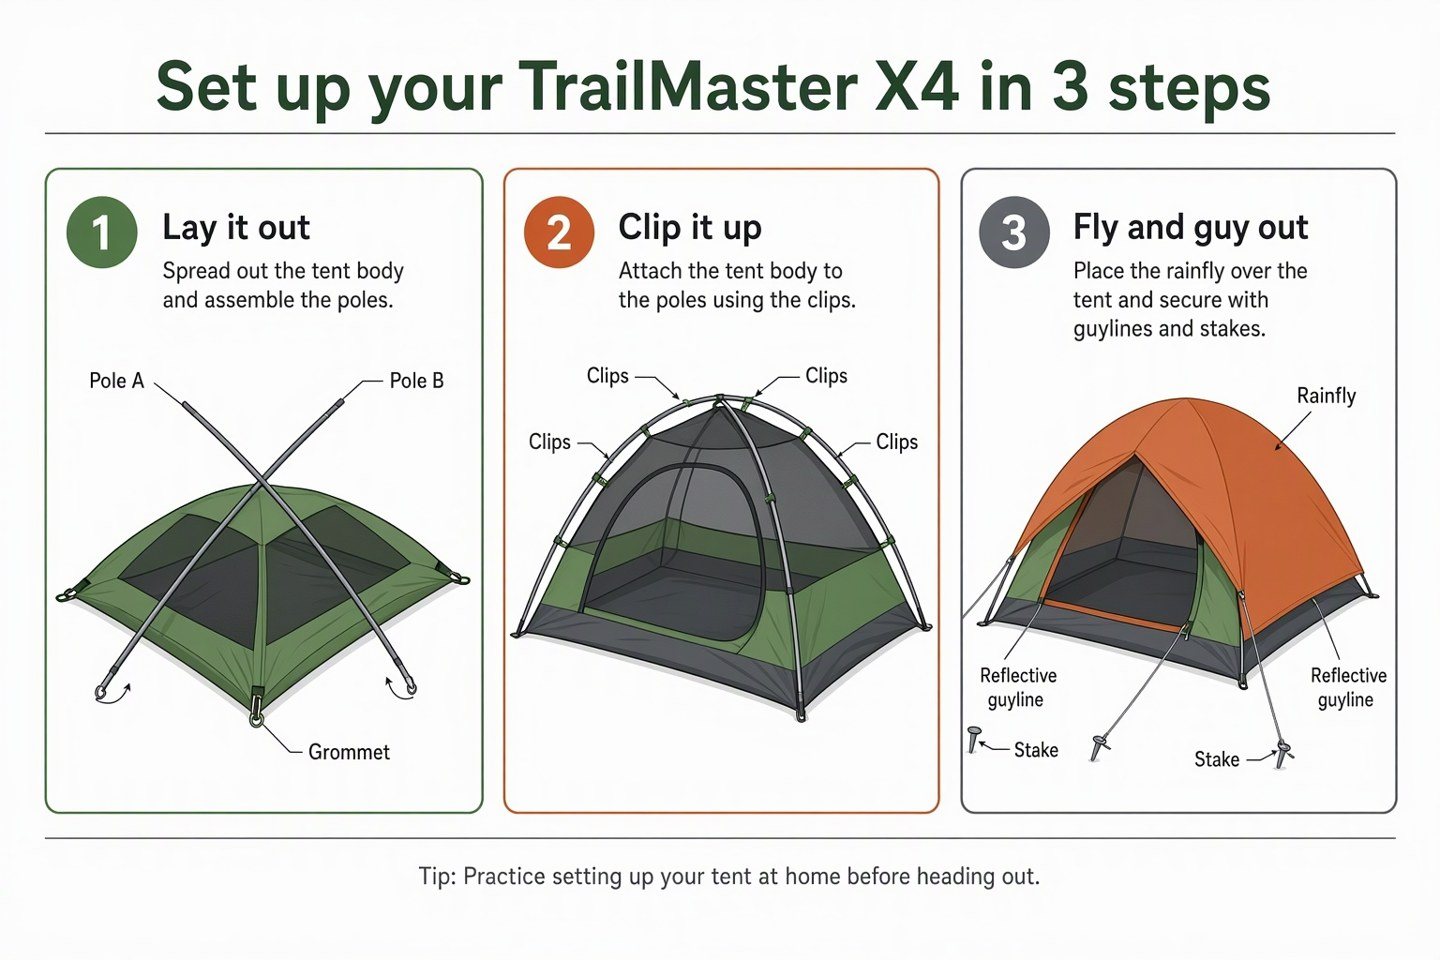

In [12]:
SETUP_GUIDE = f"""A clean instructional infographic in a flat vector style on a white background.
Title across the top: "Set up your TrailMaster X4 in 3 steps".
Three numbered panels, left to right, in green, orange and grey only:
1 "Lay it out": the green tent body flat on the ground, two grey poles labeled "Pole A" and "Pole B" crossing in an X, with arrows showing each pole end going into a corner ring labeled "Grommet".
2 "Clip it up": the tent body standing, with small clips labeled "Clips" attaching the body to the poles.
3 "Fly and guy out": the burnt-orange rainfly labeled "Rainfly" over the top, grey cords labeled "Reflective guyline" running down to pegs labeled "Stake".
Thin leader lines connect every label to the exact part it names."""

guide = generate(SETUP_GUIDE, "11-setup-guide", size=(1536, 1024))
show({"Setup guide": guide}, height=480)

👀 **What to look for:**

- [ ] Is the title spelled right, and are the steps numbered 1, 2, 3?
- [ ] Does every label point to the right part? (*Rainfly* to the rainfly, *Stake* to a stake.)
- [ ] Do the arrows in step 1 go where the poles go?

⚠️ **The honest limit:** treat diagrams as a **strong first draft**. Have someone who knows the product check
every label before it ships. A wrong arrow in a setup guide is worse than no arrow.

🧪 **Try it yourself:** ask for an **exploded view** instead: every part of the tent floating apart, with labels.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.12 Magic eraser

<img src="./assets/asks/01-12.svg" alt="Your customer asks: We have thousands of photos already. Can it fix them instead of starting over?" width="900" />
<br/>

Now we switch from making pictures to **editing** them. First we make a campsite photo with three problems.
There's a stranger in the background, the old price on the sign, and a rainfly color we want to change. Then we
fix one problem at a time, and each fix builds on the last.

> 🔮 **Guess first:** when we remove the stranger, will anything *else* in the photo change?

🔁 12-campsite-before · MAI-Image-2.6 · 27.7 s (saved earlier) · 1536×1024
🔁 12-edit-1-remove-stranger · MAI-Image-2.6 · 17.5 s (saved earlier) · 1248×832
🔁 12-edit-2-new-price · MAI-Image-2.6 · 18.0 s (saved earlier) · 1248×832
🔁 12-edit-3-new-color · MAI-Image-2.6 · 16.6 s (saved earlier) · 1248×832



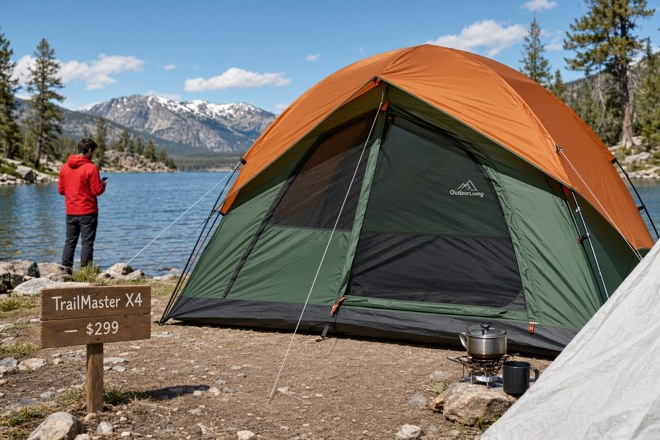
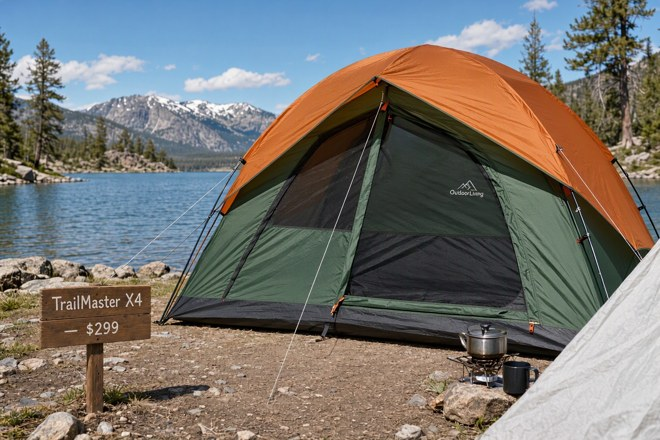
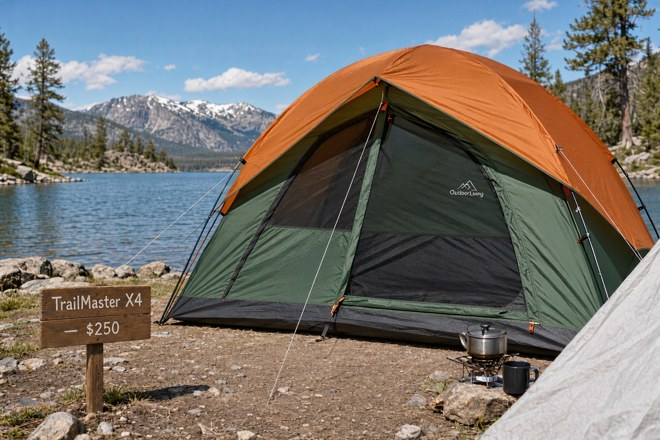
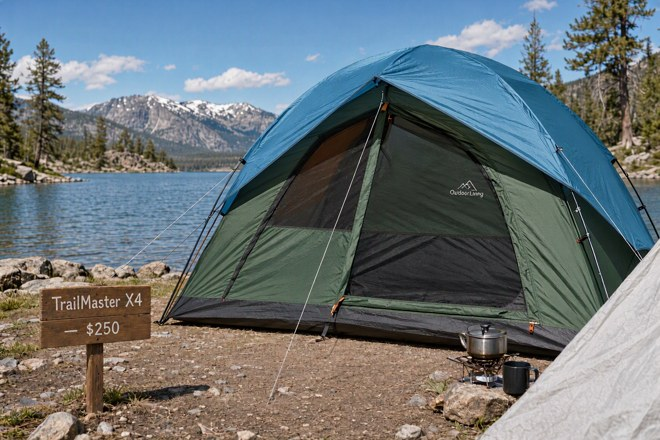

In [13]:
CAMPSITE = f"""Photo of a lakeside campsite at midday. On the right: the {TENT}, {LOOK}.
In the background on the left, a stranger in a bright red jacket stands on the shore, looking at a phone.
In the foreground, a small wooden sign on a stake reads "TrailMaster X4 — $299"."""

campsite = generate(CAMPSITE, "12-campsite-before", size=(1536, 1024))

no_stranger = edit("Remove the person in the red jacket from the background, and fill in the lake shore naturally. Change nothing else.",
                   [campsite], "12-edit-1-remove-stranger")
new_price = edit("Change the price on the wooden sign from $299 to $250. Keep the same lettering style, wood and light. Change nothing else.",
                 [no_stranger], "12-edit-2-new-price")
new_color = edit("Change the tent's rainfly from burnt orange to glacier blue. Keep the tent's shape, logo, shadows and everything else exactly the same.",
                 [new_price], "12-edit-3-new-color")

show({"Before": campsite, "1 · Stranger gone": no_stranger, "2 · New price": new_price, "3 · New color": new_color}, height=220)

Now drag the slider. This compares the very first photo with the final one, after all three edits.


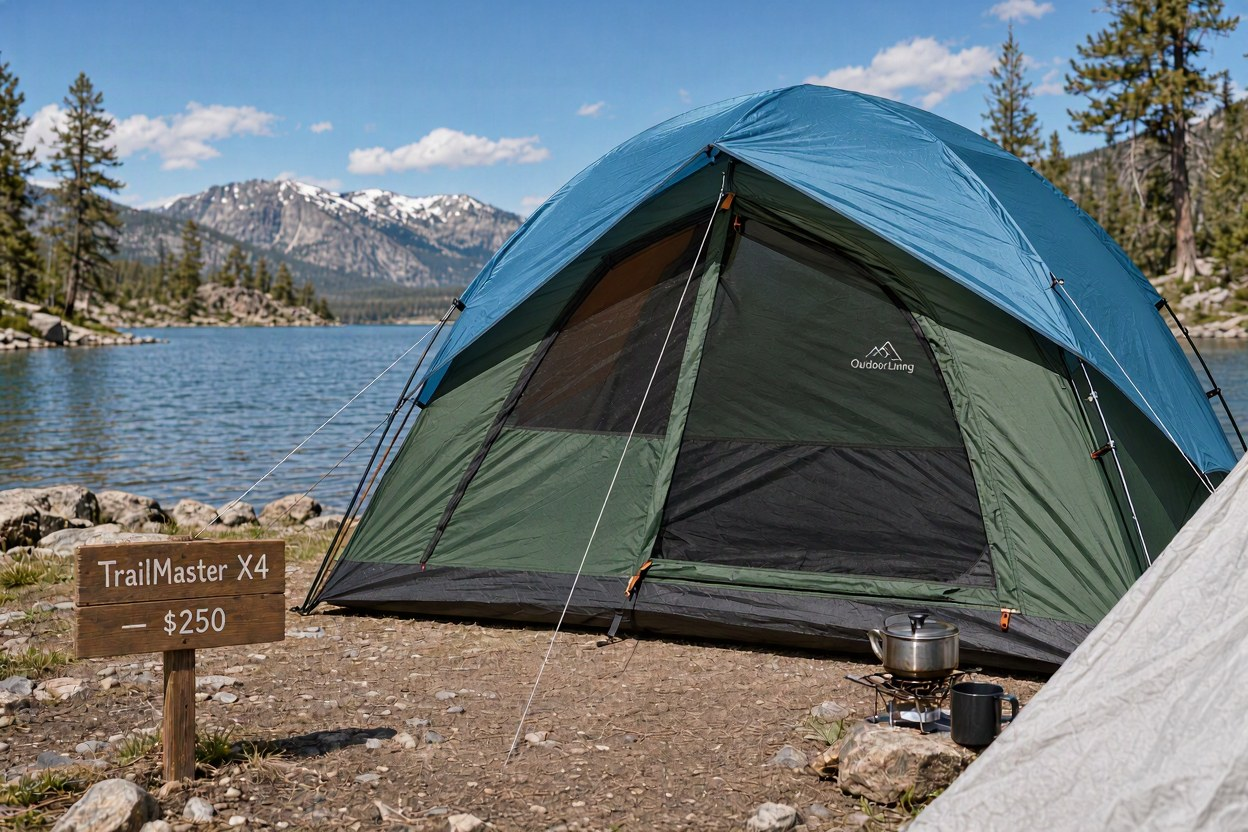
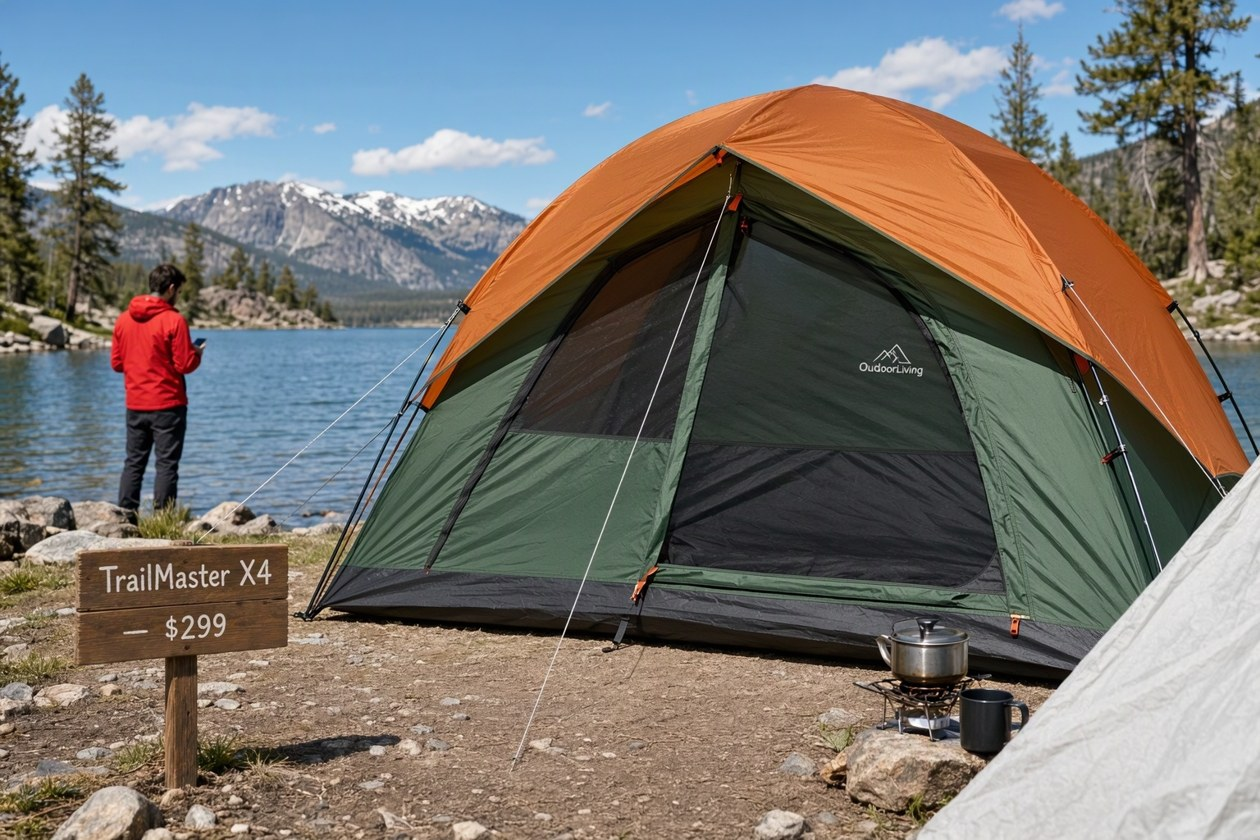

In [14]:
before_after(campsite, new_color)

👀 **What to look for:** everything that *should not* change. The lake, the trees, the shadows, the tent's
shape. Great edits are as much about what stays the same as what changes.

⚠️ **The honest limit:** each edit is a fresh picture, so tiny details can drift a little with every step.
For long chains of edits, compare the last picture with the first, like we just did.

🧪 **Try it yourself:** run `before_after(new_price, new_color)` to check *only* the color change.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.13 The impossible photoshoot

<img src="./assets/asks/01-13.svg" alt="Your customer asks: Can we put our real products together in one scene, without a photo shoot?" width="900" />
<br/>

This is the big one. The edits API takes **up to five reference images**. We'll make five clean studio shots:
four real products from the Contoso catalog, plus a model. Then we ask for **one lifestyle photo** that uses all five.

We make the props with **Flash**, the faster model, because studio shots on white are routine work. The final
photo uses **MAI-Image-2.6**, with `auto_aspect_ratio` on, so the model picks the best shape for the scene.

> 🔮 **Guess first:** which product is most likely to lose its details in the final scene?

🔁 13-prop-tent · MAI-Image-2.6-Flash · 9.8 s (saved earlier) · 1024×1024
🔁 13-prop-backpack · MAI-Image-2.6-Flash · 9.7 s (saved earlier) · 1024×1024
🔁 13-prop-stove · MAI-Image-2.6-Flash · 9.2 s (saved earlier) · 1024×1024
🔁 13-prop-hiker · MAI-Image-2.6-Flash · 9.4 s (saved earlier) · 1024×1024
🔁 13-prop-sleeping-bag · MAI-Image-2.6-Flash · 9.3 s (saved earlier) · 1024×1024



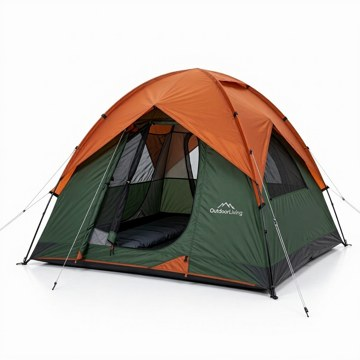
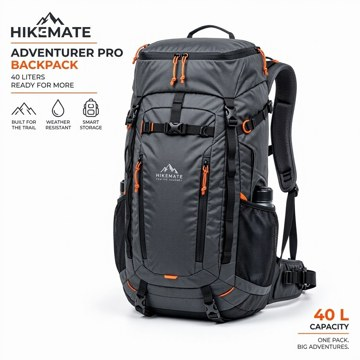
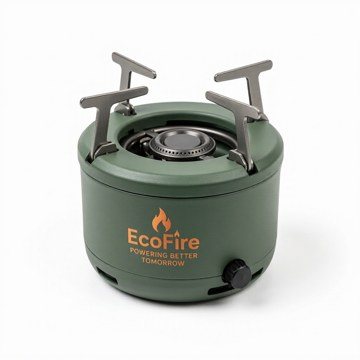
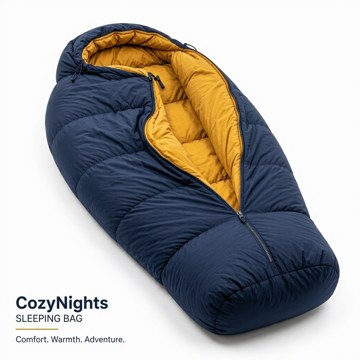
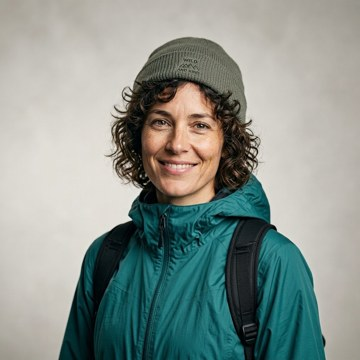

In [15]:
PROPS = {
    "tent": f"Studio product photo on a plain white background: the {TENT}, {LOOK}, pitched, three-quarter front view.",
    "backpack": "Studio product photo on a plain white background: the Adventurer Pro Backpack by HikeMate, a 40-liter charcoal-grey hiking pack with orange zip pulls, a lid pocket and side mesh bottle pockets.",
    "stove": "Studio product photo on a plain white background: the EcoFire Camping Stove, a compact single-burner stove with a matte-green base, folding steel pot supports and a small orange EcoFire logo.",
    "sleeping-bag": "Studio product photo on a plain white background: the CozyNights Sleeping Bag, a navy mummy-style sleeping bag with a mustard-yellow lining, half unzipped.",
    "hiker": "Studio portrait on a plain light-grey background of a fictional hiker in her thirties with short curly hair, smiling, wearing a teal rain jacket and a knit beanie.",
}

# Five props at once. Each deployment still keeps to its own speed limit.
with ThreadPoolExecutor(max_workers=5) as pool:
    jobs = {name: pool.submit(generate, prompt, f"13-prop-{name}", FLASH) for name, prompt in PROPS.items()}
props = {name: job.result() for name, job in jobs.items()}
show({f"{number} · {name}": path for number, (name, path) in enumerate(props.items(), start=1)}, height=180)

Five references in, one photo out. Notice how the prompt refers to each reference by its **number**.

🔁 13-impossible-photoshoot · MAI-Image-2.6 · 32.1 s (saved earlier) · 1024×1024



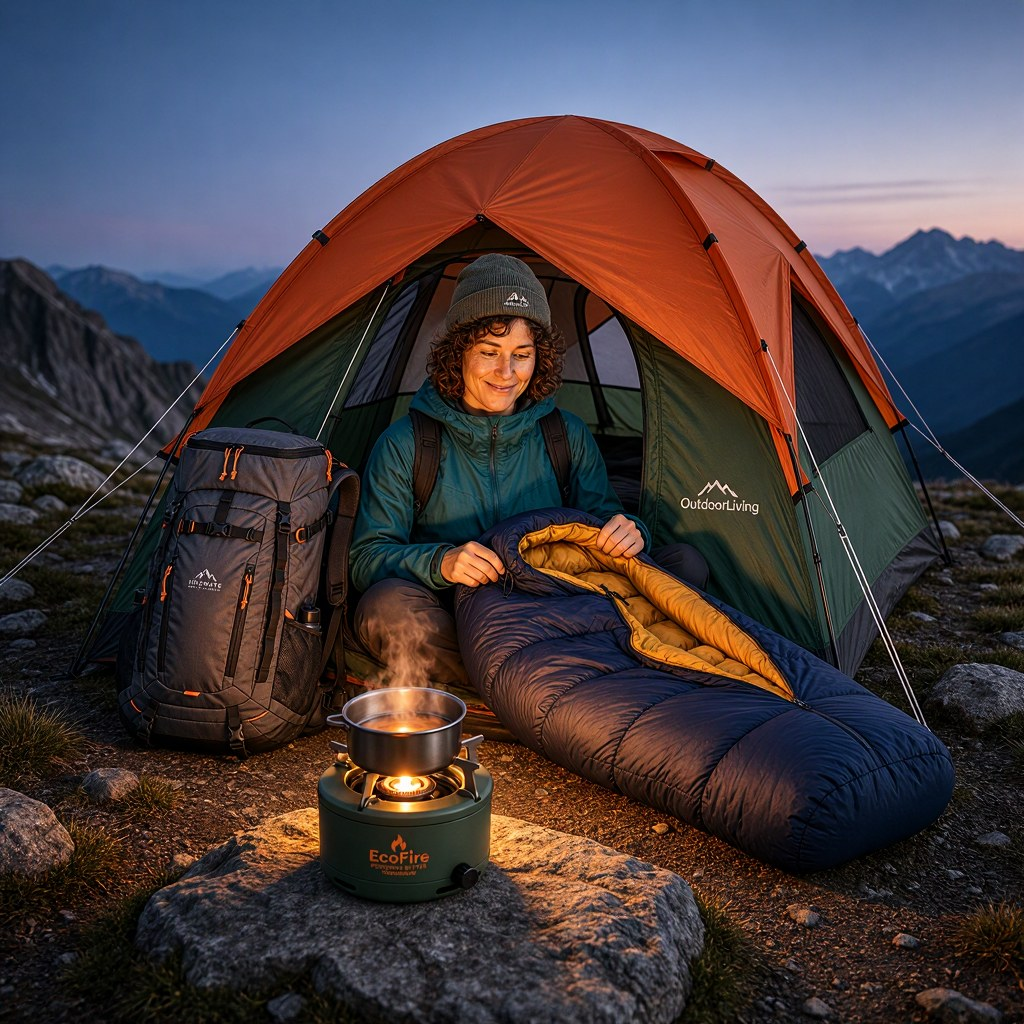

In [16]:
PHOTOSHOOT = """One lifestyle campaign photo that uses all five reference images.
At dusk on an alpine ridge, the woman from image 5 sits in the open doorway of the tent from image 1, unrolling the sleeping bag from image 4.
The backpack from image 2 leans against the tent. The stove from image 3 burns on a flat rock in front of her, with a small pot steaming.
Keep every product's colors, logos and details exactly as in its reference. Warm lantern light, natural and unposed."""

photoshoot = edit(PHOTOSHOOT, list(props.values()), "13-impossible-photoshoot", HERO, auto_aspect_ratio=True)
show({"The photoshoot that never happened": photoshoot}, height=520)

👀 **What to look for:** go product by product. Orange zip pulls on the pack? Green base on the stove? Mustard
lining in the bag? Then check the scene: does the light on each product match the dusk light?

⚠️ **The honest limit:** with five references, the smallest details (logos, zip pulls) are the first to slip.
For hero product shots, use fewer references, and put the most important product first.

🧪 **Try it yourself:** swap the hiker for the **TrekReady Hiking Boots** and ask for a close-up of boots by the tent door.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.14 What's happening this weekend?

<img src="./assets/asks/01-14.svg" alt="Your customer asks: Our campaigns depend on what&#x27;s happening right now. Can it keep up?" width="900" />
<br/>

Models learn from data up to a certain date. So how would one know *this week's* weather? With **web
grounding**, MAI-Image-2.6 can look things up with Bing before it draws. Let's make the same window poster
twice, once without grounding and once with it, and check both against a real forecast.

> 🔮 **Guess first:** without grounding, what will it put on the forecast?

📅 Today is Monday 09 November 2026. Open a weather site for Seattle, so you can check.
🔁 14-window-no-grounding · MAI-Image-2.6 · 31.9 s (saved earlier) · 1024×1280
🔁 14-window-grounded · MAI-Image-2.6 · 41.0 s (saved earlier) · 1024×1280



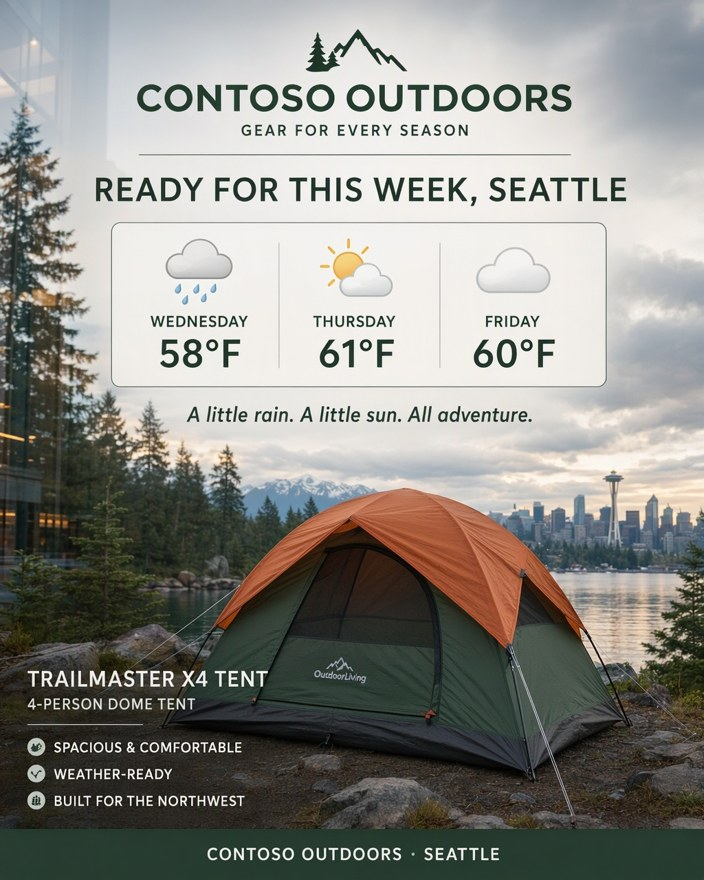
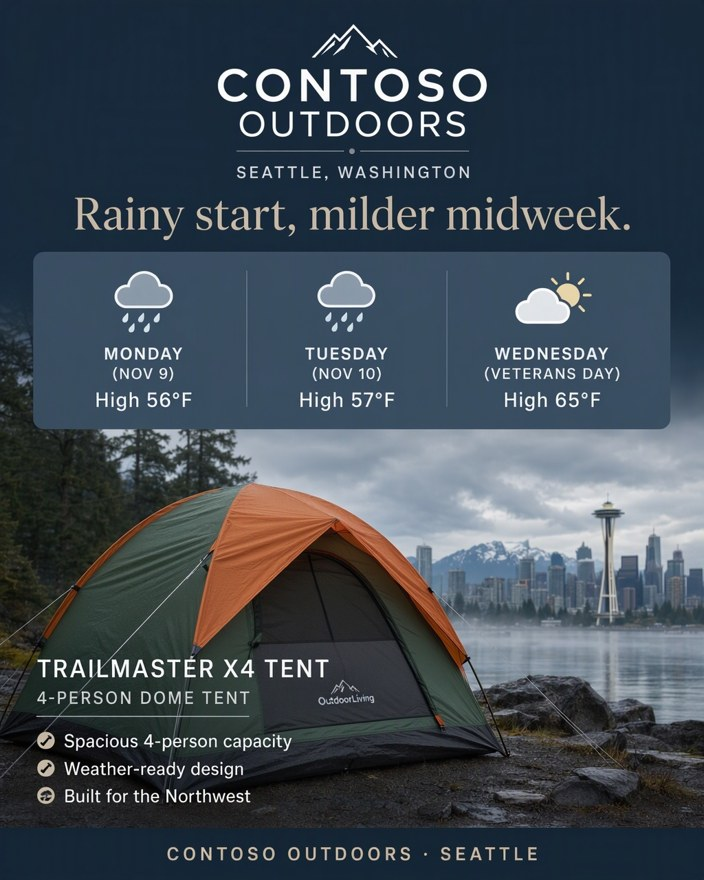

In [17]:
WINDOW = f"""A store window poster for Contoso Outdoors in Seattle, Washington, for this week.
Show the real weather forecast for Seattle for the next three days: three simple weather icons, each with its day name and high temperature in °F.
Add a short headline that suits this week's weather, and the {TENT} ({LOOK}) in a matching scene.
Footer: "Contoso Outdoors · Seattle"."""

print(f"📅 Today is {date.today():%A %d %B %Y}. Open a weather site for Seattle, so you can check.")
without = generate(WINDOW, "14-window-no-grounding", size=(1024, 1280), web_grounding=False)
grounded = generate(WINDOW, "14-window-grounded", size=(1024, 1280), web_grounding=True)
show({"Grounding off": without, "Grounding on": grounded}, height=440)

👀 **What to look for:** compare both posters with the real forecast. Right days of the week? Temperatures
close? Does the headline match the weather, sunny or rainy?

⚠️ **The honest limit:** grounding makes a picture *more likely* to be current. It doesn't make it *guaranteed*.
Always check facts, prices and dates before a picture goes live. And before using grounding with private
information, read how it works in the [MAI image docs](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image).

🧪 **Try it yourself:** ask for a poster about *"the next big outdoor event in Seattle"*, with grounding on. Then check that the event is real.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.15 Let the model frame it

<img src="./assets/asks/01-15.svg" alt="Your customer asks: We need every format: banners, phone stories, squares. Do we crop by hand?" width="900" />
<br/>

Two ways to get the right shape. First, `auto_aspect_ratio`: the model reads your prompt and **picks** the
shape. Then exact sizes, for when your website needs exactly 2304 × 1024. Each side must be at least 768 pixels.
The total can be up to 2,359,296 pixels, which is 1536 × 1536.

> 🔮 **Guess first:** what shape will it pick for a panorama? And for a waterfall?

🔁 15-auto-panorama · MAI-Image-2.6 · 35.9 s (saved earlier) · 1536×1536
🔁 15-auto-waterfall · MAI-Image-2.6 · 36.3 s (saved earlier) · 1536×1536
🔁 15-auto-packshot · MAI-Image-2.6 · 34.3 s (saved earlier) · 1536×1536



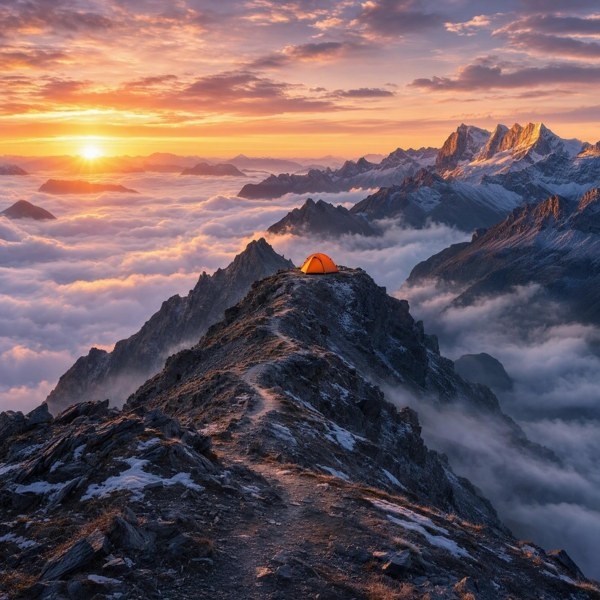
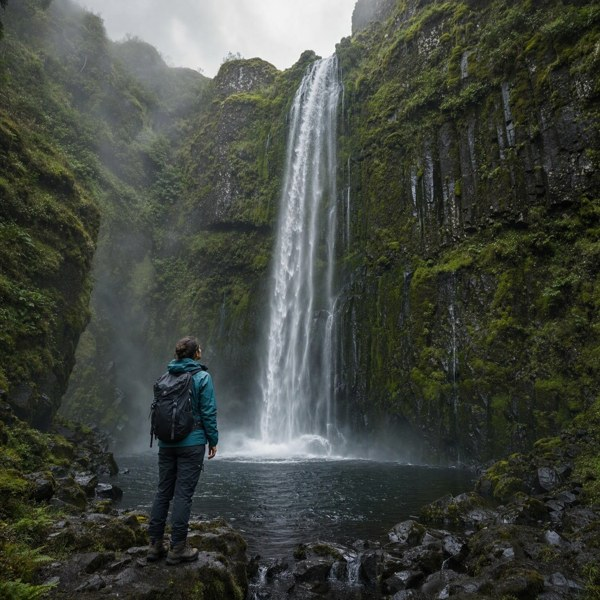
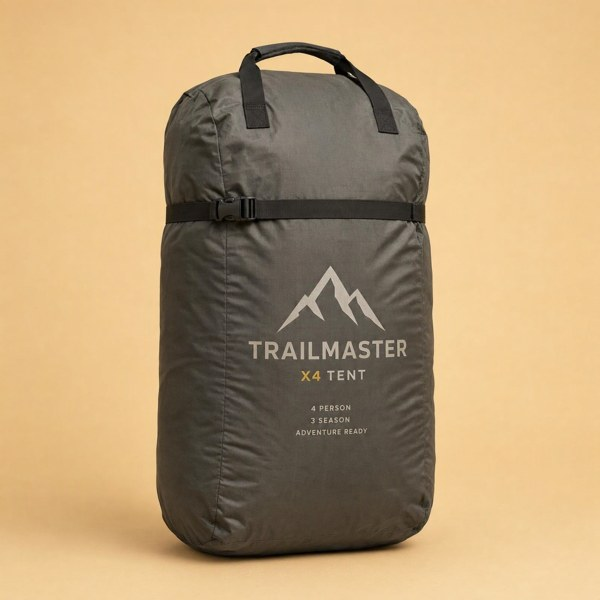

🔍 The model picked 1536×1536 every time. That's a real result, and worth knowing: when the shape matters, ask for an exact size.


In [18]:
SCENES = {
    "panorama": "A sweeping view of a long mountain ridge trail at sunrise, with a tiny orange tent far off on the ridgeline.",
    "waterfall": "A tall, narrow waterfall dropping down a mossy cliff, with a hiker in a teal jacket looking up from the pool below.",
    "packshot": f"The {TENT} packed in its carry bag, centered on a plain sand-colored background.",
}
framed = {}
for name, prompt in SCENES.items():
    path = generate(prompt, f"15-auto-{name}", size=None, auto_aspect_ratio=True)
    framed[f"{name} · {run_log[path.stem]['size']}"] = path
show(framed, height=300)

shapes = {run_log[path.stem]["size"] for path in framed.values()}
if len(shapes) == 1:
    print(f"🔍 The model picked {shapes.pop()} every time. That's a real result, and worth knowing: when the shape matters, ask for an exact size.")
else:
    print(f"🔍 The model picked {len(shapes)} different shapes for three different scenes.")

Did it pick a different shape for each scene? Or the same one every time? Either way, you've learned something
about `auto_aspect_ratio` that you can pass on to customers: when the shape really matters, ask for it.

So here are exact sizes: a wide website banner and a tall phone story. Both use the full pixel budget.

🔁 15-web-banner · MAI-Image-2.6 · 37.3 s (saved earlier) · 2304×1024
🔁 15-phone-story · MAI-Image-2.6 · 35.6 s (saved earlier) · 1152×2048



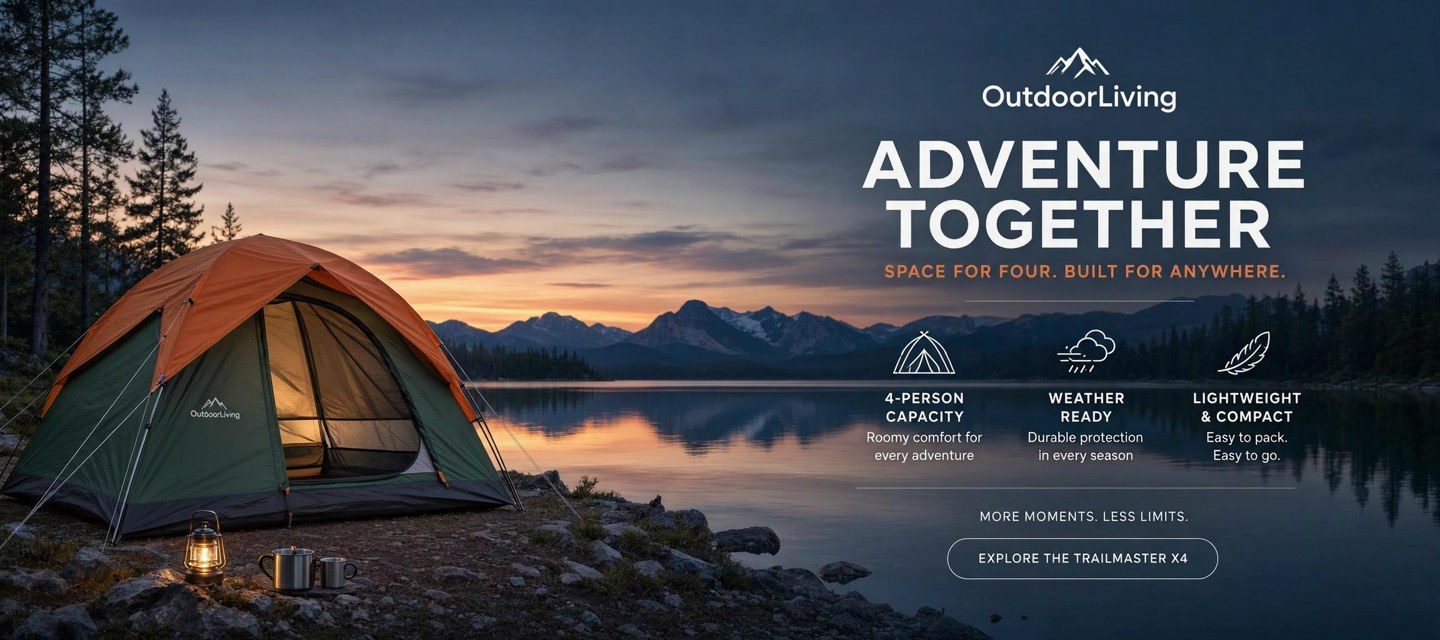
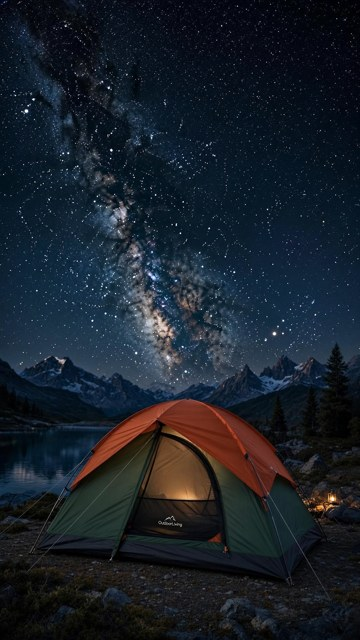

In [19]:
BANNER = f"A wide website hero banner: the {TENT} ({LOOK}) on the far left at a lakeside campsite at dusk, with calm, empty sky on the right for text."
STORY = f"A tall phone story: the {TENT} ({LOOK}) at the bottom, under a huge starry night sky and the Milky Way, with empty space at the top for a caption."

banner = generate(BANNER, "15-web-banner", size=(2304, 1024))   # 2304 × 1024 = 2,359,296 pixels: right at the limit
story = generate(STORY, "15-phone-story", size=(1152, 2048))    # 9:16, the shape of a phone screen
show({"Web banner · 2304×1024": banner, "Phone story · 1152×2048": story}, height=320)

### 🔧 Break it on purpose

What happens if you ask for more pixels than the model allows? Let's find out on purpose. A 1600 × 1600
picture is 2,560,000 pixels, just over the limit.

> 🔮 **Guess first:** will it shrink the picture to fit, or say no?

🔁 Replay has no saved result for this request. Set DEMO_MODE to live to send it.
🔁 15-just-right · MAI-Image-2.6 · 36.2 s (saved earlier) · 1536×1536



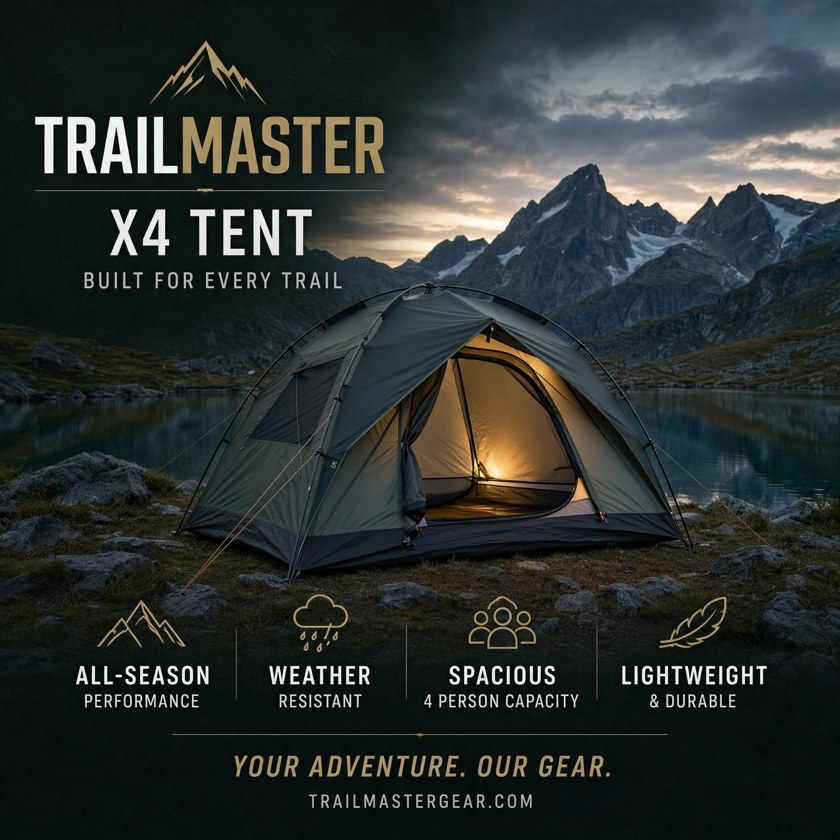

In [20]:
try:
    generate("A square poster of the TrailMaster X4 Tent.", "15-too-big", size=(1600, 1600))  # 🔴 2,560,000 pixels: over the limit
except (SystemExit, requests.RequestException) as problem:  # A network error shows up here too, if you're offline.
    print(problem)

fits = generate("A square poster of the TrailMaster X4 Tent.", "15-just-right", size=(1536, 1536))  # ✅ 2,359,296 pixels: right at the limit
show({"✅ 1536×1536: right at the limit": fits}, height=420)

You should see a **400** for the first request, and a picture for the second. The model doesn't quietly shrink
your picture. It tells you. Read the message: it usually says exactly what to change. 🔍

🧪 **Try it yourself:** what's the widest banner you can make? (Hint: the short side can't go under 768.)

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.16 Which model do you need?

<img src="./assets/asks/01-16.svg" alt="Your customer asks: Do we pay for the best model every time, or is there a cheaper option?" width="900" />
<br/>

MAI-Image-2.6 comes in two versions: **MAI-Image-2.6** and **MAI-Image-2.6-Flash**. Here's what Microsoft
says about them *(as of October 2026)*:

| | MAI-Image-2.6 | MAI-Image-2.6-Flash |
| --- | --- | --- |
| New pictures and edits, up to 5 references | ✅ | ✅ |
| Web grounding and auto aspect ratio | ✅ | ✅ |
| Biggest picture | 1536 × 1536 pixels' worth | Same |
| Longest prompt | 32,000 tokens | Same |
| Rate limit, Tier 1 to Tier 6 | 6 to 36 requests a minute | Same |
| Microsoft's description | The latest quality gains | The same abilities, faster and cheaper |

So the features are the same. The real questions are about **speed, cost and finish**. Let's measure them
instead of guessing.

### 1.16.1 Blind taste test

Four prompts, each made by both models. We shuffle them into **A** and **B**, so you can't tell which is which.

> 🔮 **Guess first:** will you be able to spot MAI-Image-2.6 every time?

🔁 16-taste-text-hero · MAI-Image-2.6 · 41.1 s (saved earlier) · 1024×1024
🔁 16-taste-text-flash · MAI-Image-2.6-Flash · 10.0 s (saved earlier) · 1024×1024
🔁 16-taste-materials-hero · MAI-Image-2.6 · 31.3 s (saved earlier) · 1024×1024
🔁 16-taste-instructions-hero · MAI-Image-2.6 · 25.6 s (saved earlier) · 1024×1024
🔁 16-taste-instructions-flash · MAI-Image-2.6-Flash · 10.0 s (saved earlier) · 1024×1024
🔁 16-taste-materials-flash · MAI-Image-2.6-Flash · 10.7 s (saved earlier) · 1024×1024
🔁 16-taste-portrait-flash · MAI-Image-2.6-Flash · 10.0 s (saved earlier) · 1024×1024
🔁 16-taste-portrait-hero · MAI-Image-2.6 · 23.0 s (saved earlier) · 1024×1024



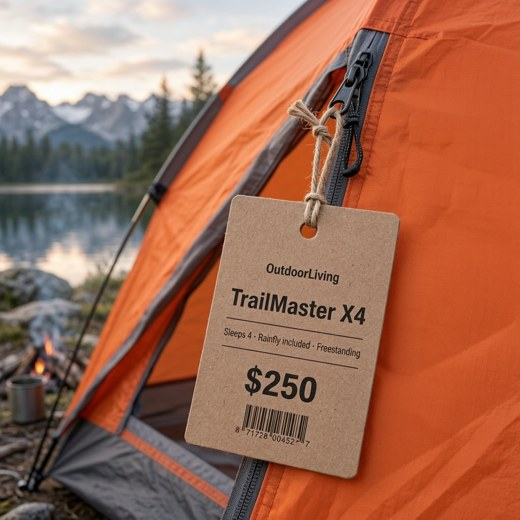
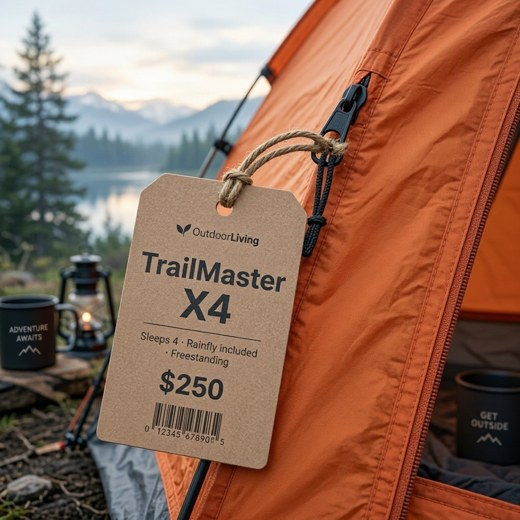


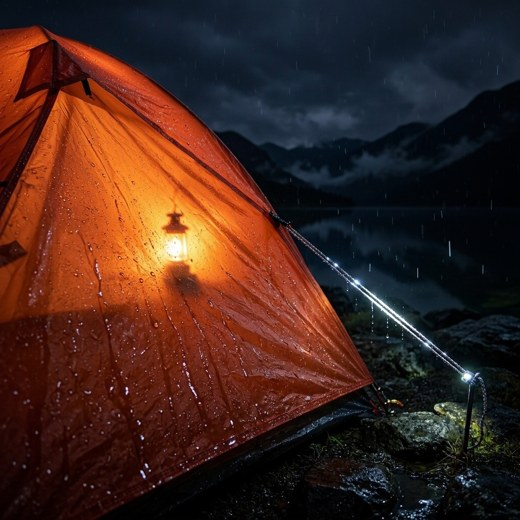
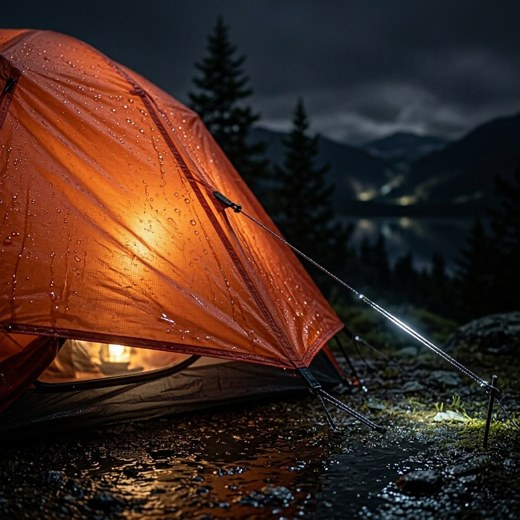


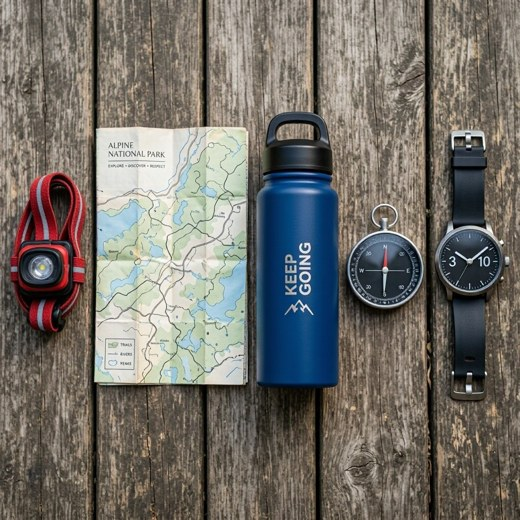
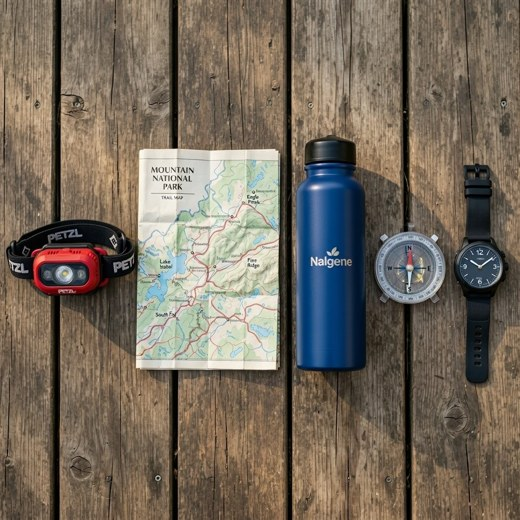


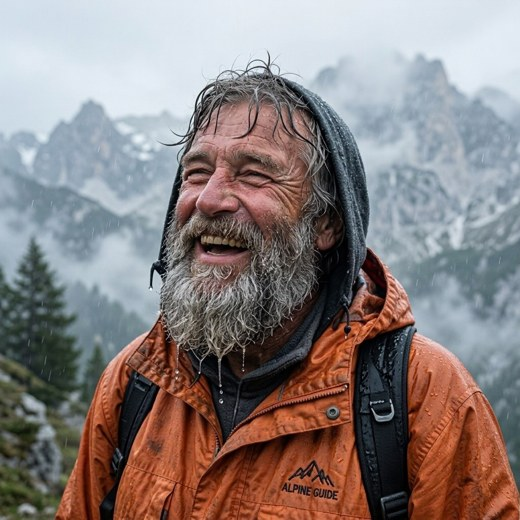
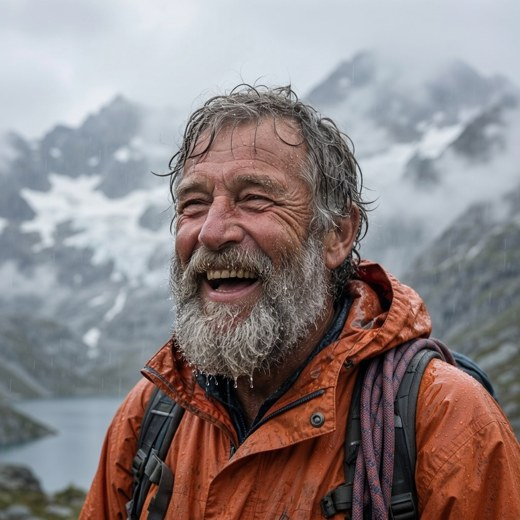

In [21]:
TASTE_TESTS = {
    "text": "A kraft-paper hang tag tied with twine to the zipper of an orange tent. Printed on it: 'OutdoorLiving' (small), 'TrailMaster X4' (large), 'Sleeps 4 · Rainfly included · Freestanding' (small), '$250' (bold), and a small barcode.",
    "materials": "Close-up of a burnt-orange tent rainfly at night, glowing from a lantern inside, rain beads shining on the fabric, and a reflective guyline catching a headlamp beam.",
    "instructions": "Overhead flat-lay on a wooden deck: exactly five items in one row, left to right: a red headlamp, a folded map, a blue water bottle, a compass whose needle points to the top of the image, and a wristwatch showing 3:10.",
    "portrait": "Portrait of a fictional mountain guide in his sixties, laughing, rain in his grey beard, wearing a faded orange jacket, soft overcast light, shallow depth of field.",
}

# Both models run side by side. Each keeps to its own rate limit.
with ThreadPoolExecutor(max_workers=8) as pool:
    jobs = {(test, model): pool.submit(generate, prompt, f"16-taste-{test}-{'flash' if model == FLASH else 'hero'}", model)
            for test, prompt in TASTE_TESTS.items() for model in (HERO, FLASH)}
taste = {key: job.result() for key, job in jobs.items()}

shuffle = random.Random(2026)  # A fixed seed, so replay mode shows the same A and B every time.
secret = {test: shuffle.sample([HERO, FLASH], 2) for test in TASTE_TESTS}
for test, (model_a, model_b) in secret.items():
    show({f"{test} · A": taste[(test, model_a)], f"{test} · B": taste[(test, model_b)]}, height=260)

Cast your votes, then reveal. Which did you like better for each test, **A** or **B**?

In [22]:
# ✏️ Put "A" or "B" for each test, then run the cell.
# my_votes = {"text": "", "materials": "", "instructions": "", "portrait": ""}
my_votes = {"text": "B", "materials": "A", "instructions": "A", "portrait": "B"}


for test, (model_a, model_b) in secret.items():
    vote = my_votes.get(test, "").strip().upper()
    picked = {"A": model_a, "B": model_b}.get(vote)
    seconds = {model: run_log[taste[(test, model)].stem]["seconds"] for model in (HERO, FLASH)}
    reveal = f"A was {model_a}, B was {model_b}"
    choice = f"you picked {picked}" if picked else "no vote yet"
    print(f"{test:>12}: {reveal} · {choice} · {HERO} {seconds[HERO]} s, {FLASH} {seconds[FLASH]} s")

        text: A was MAI-Image-2.6, B was MAI-Image-2.6-Flash · you picked MAI-Image-2.6-Flash · MAI-Image-2.6 41.1 s, MAI-Image-2.6-Flash 10.0 s
   materials: A was MAI-Image-2.6, B was MAI-Image-2.6-Flash · you picked MAI-Image-2.6 · MAI-Image-2.6 31.3 s, MAI-Image-2.6-Flash 10.7 s
instructions: A was MAI-Image-2.6-Flash, B was MAI-Image-2.6 · you picked MAI-Image-2.6-Flash · MAI-Image-2.6 25.6 s, MAI-Image-2.6-Flash 10.0 s
    portrait: A was MAI-Image-2.6-Flash, B was MAI-Image-2.6 · you picked MAI-Image-2.6 · MAI-Image-2.6 23.0 s, MAI-Image-2.6-Flash 10.0 s


### 1.16.2 The scoreboard

Opinions are great. Numbers are better. This cell turns the taste test into a scoreboard: the typical time per
picture for each model. Add today's prices to `.env`, and it also shows what 100 or 10,000 pictures would cost.

In [23]:
def seconds_for(model: str) -> list[float]:
    return [run_log[path.stem]["seconds"] for (test, made_by), path in taste.items() if made_by == model]


prices = {HERO: setting("PRICE_PER_IMAGE_HERO_USD", ""), FLASH: setting("PRICE_PER_IMAGE_BULK_USD", "")}
print(f"{'':<22}{'Typical time':>14}{'100 pictures':>16}{'10,000 pictures':>18}")
for model in (HERO, FLASH):
    typical = statistics.median(seconds_for(model))
    price = float(prices[model]) if prices[model] else None
    cost_100 = f"${price * 100:,.2f}" if price else "add a price"
    cost_10k = f"${price * 10_000:,.2f}" if price else "add a price"
    print(f"{model:<22}{typical:>12.1f} s{cost_100:>16}{cost_10k:>18}")

speedup = statistics.median(seconds_for(HERO)) / statistics.median(seconds_for(FLASH))
print(f"\n⚡ In your run, {FLASH} took about {1 / speedup:.0%} of the time {HERO} took.")
print(f"🚦 Both share the same speed limit: {REQUESTS_PER_MINUTE} requests a minute at your tier.")

                        Typical time    100 pictures   10,000 pictures
MAI-Image-2.6                 28.5 s     add a price       add a price
MAI-Image-2.6-Flash           10.0 s     add a price       add a price

⚡ In your run, MAI-Image-2.6-Flash took about 35% of the time MAI-Image-2.6 took.
🚦 Both share the same speed limit: 5 requests a minute at your tier.


👀 **What to look for:** your *own* numbers. Speed depends on your region, the time of day and the prompt.
Microsoft's launch post compares Flash with a *different* model (GPT-Image-2-Medium), not with MAI-Image-2.6.
So the numbers from your run are the ones to share.

### 1.16.3 Draft on Flash, finish on MAI-Image-2.6

Here's the pattern we'd suggest to most customers. Use **Flash**, the faster model, to **explore** six ideas. Pick a favorite.
Then hand it to **MAI-Image-2.6** to **finish** it, keeping the idea you picked.

> 🔮 **Guess first:** will the finished picture keep the layout of the draft?

🔁 16-draft-1 · MAI-Image-2.6-Flash · 10.1 s (saved earlier) · 1024×1024
🔁 16-draft-2 · MAI-Image-2.6-Flash · 10.3 s (saved earlier) · 1024×1024
🔁 16-draft-3 · MAI-Image-2.6-Flash · 10.4 s (saved earlier) · 1024×1024
🔁 16-draft-4 · MAI-Image-2.6-Flash · 9.9 s (saved earlier) · 1024×1024
🔁 16-draft-6 · MAI-Image-2.6-Flash · 9.1 s (saved earlier) · 1024×1024
🔁 16-draft-5 · MAI-Image-2.6-Flash · 10.0 s (saved earlier) · 1024×1024



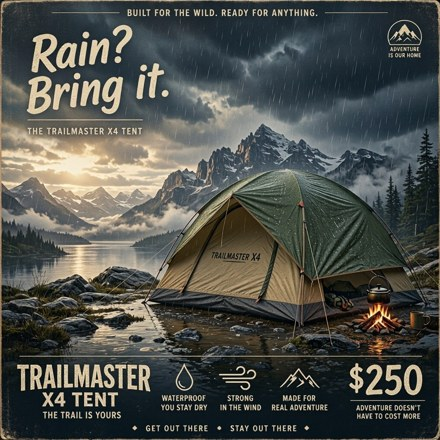
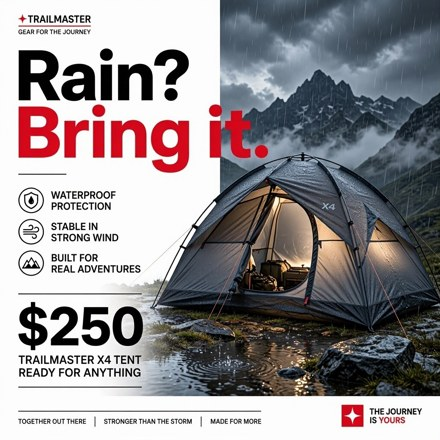
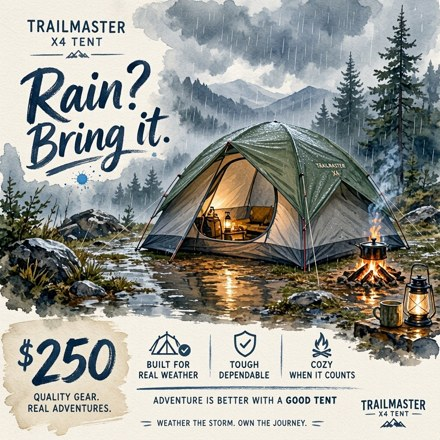
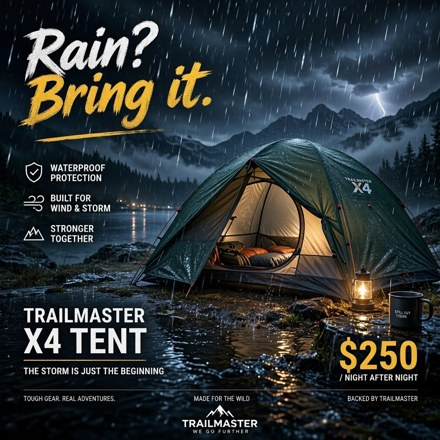
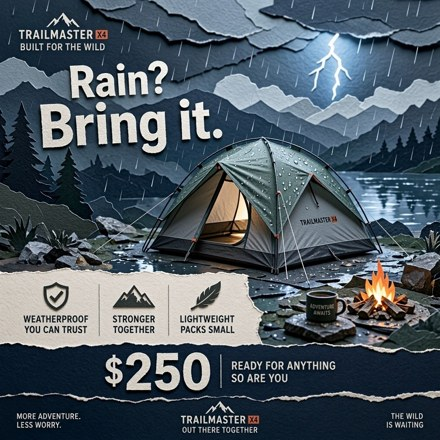
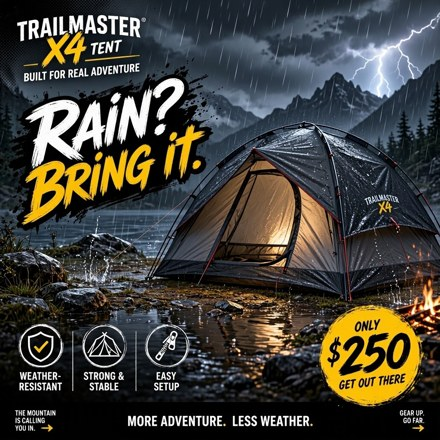

In [24]:
STYLES = ["a 1970s screen-printed national-park poster", "a bold minimal Swiss-style poster", "a cozy loose watercolor",
          "a cinematic night photo in heavy rain", "a layered papercut diorama", "a playful comic-book panel"]
AD = f'An ad for the {TENT} with the headline "Rain? Bring it." and the price "$250". Style: {{style}}.'

with ThreadPoolExecutor(max_workers=6) as pool:
    jobs = [pool.submit(generate, AD.format(style=style), f"16-draft-{number}", FLASH) for number, style in enumerate(STYLES, start=1)]
drafts = [job.result() for job in jobs]
show({f"Draft {number}": path for number, path in enumerate(drafts, start=1)}, height=220)

Pick your favorite. Change `WINNER` to its number, then run the cell. MAI-Image-2.6 gets the draft as a reference.

In [ ]:
WINNER = 2  # ✏️ Your favorite draft, from 1 to 6

FINISH = """Re-create this concept as the final campaign image. Keep the same layout, style and idea.
Make the detail sharper, the lighting richer and the typography cleaner.
Spell the headline exactly "Rain? Bring it." and the price exactly "$250"."""

final_ad = edit(FINISH, [drafts[WINNER - 1]], f"16-final-from-draft-{WINNER}", HERO)
before_after(drafts[WINNER - 1], final_ad)

### 1.16.4 So which one should you pick?

| Pick **MAI-Image-2.6-Flash** when… | Pick **MAI-Image-2.6** when… |
| --- | --- |
| You need lots of pictures: catalog backgrounds, ad variations, personal touches | It's a hero picture people will study |
| Someone is waiting, like inside an app | There's a lot of text on the picture |
| You're exploring ideas and drafts | Close-ups need materials that look real |
| You're doing routine edits, like cleanup | You're combining several references into one scene |
| | It's the final, full-size version |

**Not sure? Use both.** Draft on Flash, finish on MAI-Image-2.6, just like we did.

🗣️ **Four questions to ask a customer:**

1. How many pictures do you need a day?
2. Is a person waiting for each one?
3. Is there text on the picture?
4. Will it be seen as a thumbnail, or on a billboard?

Lots of pictures, someone waiting, little text, small screens: start with **Flash**. The other way round:
start with **MAI-Image-2.6**.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.17 The launch kit 🎉

Let's step back and look at what we made. This cell gathers every picture from this session into one contact
sheet. It also adds up how many pictures each model made, and how long they took.

> 🔮 **Guess first:** how many pictures do you think we made?


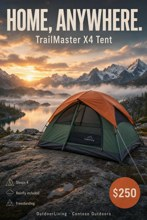
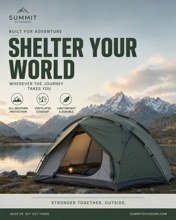
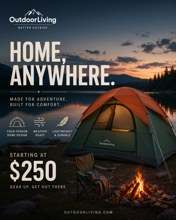
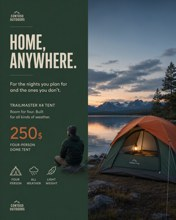
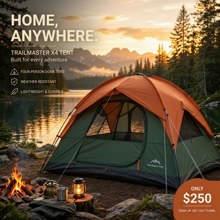
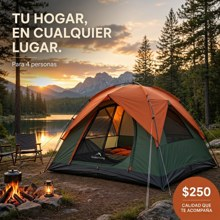
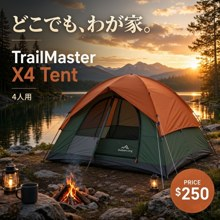
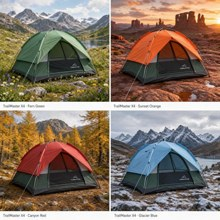
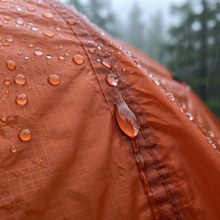
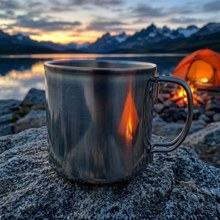
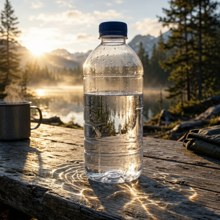
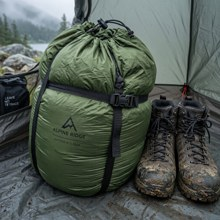
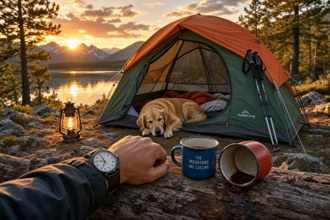
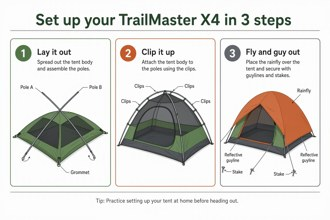
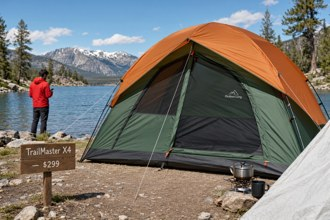
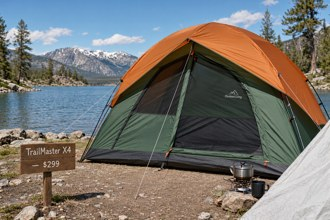
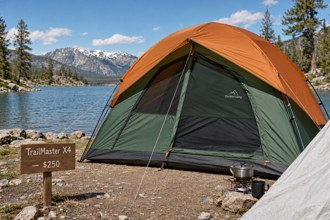
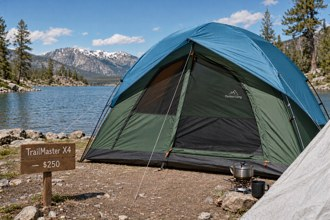
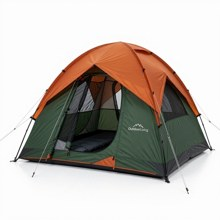
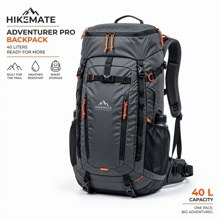
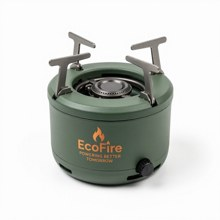
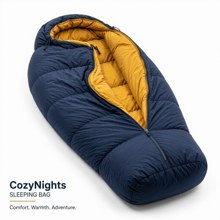
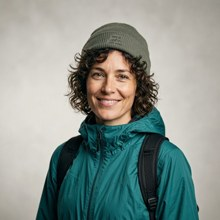
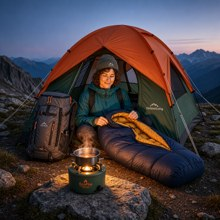
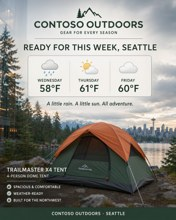
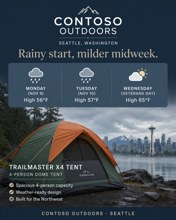
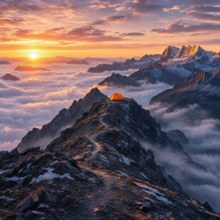
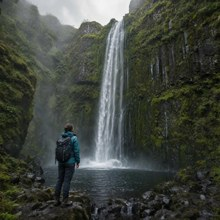
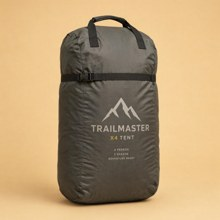
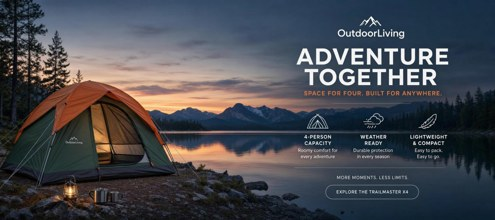
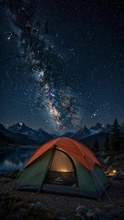
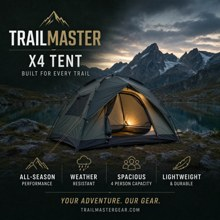
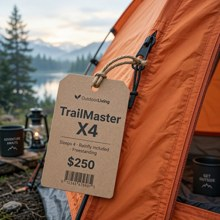
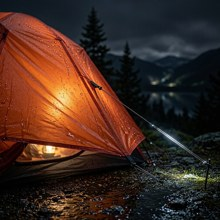
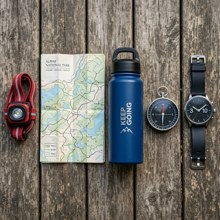
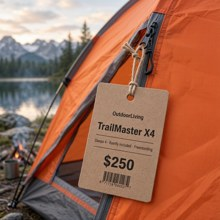
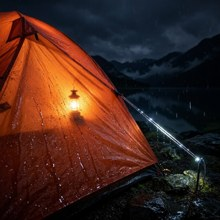
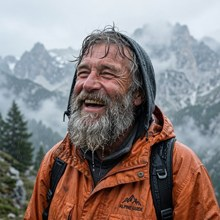
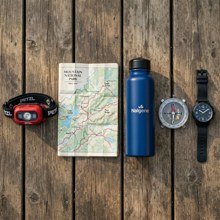
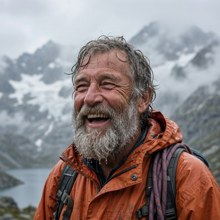
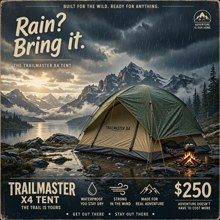
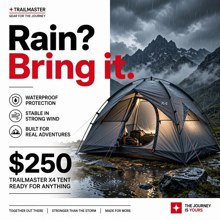
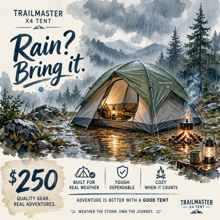
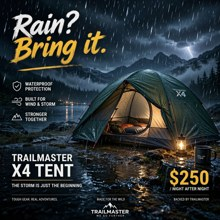
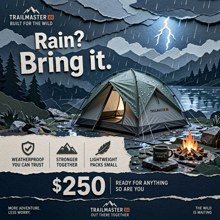
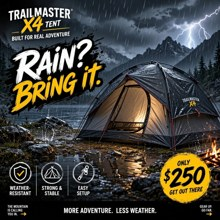
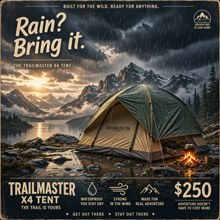

🎨 47 pictures for the TrailMaster X4 Tent launch

   MAI-Image-2.6: 32 pictures · 15.5 minutes of drawing
   MAI-Image-2.6-Flash: 15 pictures · 2.5 minutes of drawing

💡 For the exact bill, open Cost analysis for your resource group in the Azure portal.


In [25]:
made = [(name, entry) for name, entry in run_log.items() if saved(name)]
show({name.split("-", 1)[1]: saved(name) for name, _ in made}, height=110)

print(f"🎨 {len(made)} pictures for the {TENT} launch\n")
for model in (HERO, FLASH):
    times = [entry["seconds"] for _, entry in made if entry["model"] == model]
    if times:
        price = setting(f"PRICE_PER_IMAGE_{'HERO' if model == HERO else 'BULK'}_USD", "")
        cost = f" · about ${float(price) * len(times):,.2f}" if price else ""
        print(f"   {model}: {len(times)} pictures · {sum(times) / 60:.1f} minutes of drawing{cost}")
print("\n💡 For the exact bill, open Cost analysis for your resource group in the Azure portal.")

Posters, a catalog page, close-ups, a setup guide, a lifestyle shoot, ads in three languages, a banner, a phone
story and a finished ad. **That's a launch kit.** 🎉 Take a moment. That's a lot of pictures, and you judged
every one with a real checklist.

📸 **Show it off:** screenshot your contact sheet, or your favorite before-and-after slider, and share it with your team.

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.18 Teach it to a customer

Here's everything from today, ready for a customer conversation.

### What it can do, and why it matters

| Strength | Why a customer cares | Show them |
| --- | --- | --- |
| Text and design | Posters and packaging with fewer fix-ups | Sections 1.5 and 1.6 |
| Other languages | Local ads, with a native speaker checking | Section 1.7 |
| Product variants | Catalog pages that match | Section 1.8 |
| Materials that look real | Close-ups that hold up | Section 1.9 |
| Following detailed briefs | Fewer retries | Section 1.10 |
| Diagrams | Fast first drafts of guides | Section 1.11 |
| Edits | Fix the photos they already have | Section 1.12 |
| Up to five references | Scenes without a photo shoot | Section 1.13 |
| Web grounding | Pictures that know about now | Section 1.14 |
| Any shape | Banners and stories without cropping | Section 1.15 |
| A Flash version | The same features, faster and cheaper | Section 1.16 |

### A prompt recipe that works

1. **The subject**, described the same way every time (like our `LOOK`).
2. **The scene**: place, time of day, light.
3. **The text**, in quotes, in order of importance.
4. **The layout**: what goes where.
5. **What to keep the same**, for edits: *"Change nothing else."*

### Honest answers to common questions

| They ask… | You can say… |
| --- | --- |
| Is it ready for production? | Yes: MAI-Image-2.6 and MAI-Image-2.6-Flash are **generally available** in Microsoft Foundry ([launch post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/)). Still pilot it on your own prompts first. |
| Can we use our brand guide? | Yes. Prompts can be up to 32,000 tokens. Expect fewer revision rounds, not zero. |
| Does it do our language? | Prompts work best in English. Text in pictures is strongest in English. Review the rest. |
| Is it current? | With web grounding, it can look things up. Still check the facts. |
| How fast can we go? | That depends on your rate limit tier. Run section 1.16 in their region. |
| What does it cost? | Pay as you go. Check the [pricing page](https://aka.ms/MAIModelPricing) for today's prices. |
| Is it safe for real people? | Use it for fictional people. Don't impersonate real ones. See the model card. |

### When something goes wrong

| You see | It usually means | Try |
| --- | --- | --- |
| 400 | A size, file type or option it didn't accept | Check the size rules in section 1.15 |
| 401 | You're not signed in | Run `az login` |
| 403 | You need a role | Ask for **Foundry User** on the resource |
| 404 | No deployment with that name | Compare your `.env` with **Models + endpoints** |
| 429 | Too many requests | Wait a minute, or lower `RATE_LIMIT_RPM` |

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.19 Check yourself

1. A customer wants 5,000 product backgrounds a day for their website. Which model would you start with, and why?
2. Why do we keep the prompt in English, even when the poster is in Japanese?
3. In section 1.15, the model said **400** instead of shrinking the picture. Why is that the more helpful behavior?

<details>
<summary>Show answers</summary>

1. **MAI-Image-2.6-Flash.** It's lots of pictures, with little text, so speed and cost matter most. Try MAI-Image-2.6 on a few, and compare.
2. The model card says it reads prompts in English. Only the words *on* the picture change language.
3. A quiet shrink would hide a mistake. A clear error tells you exactly what to fix, before a wrong-sized banner ships.

</details>

### 🤖 Ask your agent

- *"Help me write a brief for MAI-Image-2.6 for a product my customer sells, using the prompt recipe from section 1.18."*
- *"Turn my clockwork scorecard into a small evaluation that runs the same prompt five times and averages the scores."*
- *"Explain web grounding to a customer in three sentences, with an everyday example."*

<img src="./assets/divider.svg" alt="" width="100%" height="6" />

## 1.20 Cost and cleanup

This notebook doesn't create any Azure resources. It only calls the two deployments you already have, and you
pay per picture. When you're done:

- **Keep `output/01/`** if you want to present with `DEMO_MODE=replay`. It stays on your computer, and Git ignores it.
- **Delete `output/01/`** to clear your saved pictures.
- **Remove everything** when you've finished the workshop: `bash infra/teardown.sh` deletes the resource group. There's no charge for a deployment you don't call.

➡️ **Next:** [02 · Give it a voice](./02-give-it-a-voice.ipynb). The ad copy you just drew becomes a radio spot. Or head back to the [workshop README](./README.md).